<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSVR_AnomalyDetection_Tscharke2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum SVR for anomaly detection under noise and attack: Tscharke et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Kilian Tscharke, Maximilian Wendlinger, Sebastian Issel and Pascal Debus, "Anomaly Detection with Quantum SVR in the NISQ Era: Limits of Robustness to Noise and Adversarial Attacks"
> (published as "Quantum Support Vector Regression for Robust Anomaly Detection"), Fraunhofer AISEC, SCITEPRESS 2025,
> DOI 10.5220/0014218600004052, arXiv:2505.01012v3 (December 2025).

The paper publishes no code. Everything below is written from the paper's description (and the method it builds on, Tscharke, Issel and Debus, IEEE QCE 2023), with the stack the paper names: PennyLane for the quantum circuit and the noise simulation, scikit-learn for the SVR.

**What the notebook does.** It downloads the paper's eleven benchmark datasets (credit-card fraud, Census, Forest Cover Type, DNS-over-HTTPS, EMNIST, Fashion-MNIST, NSL-KDD, MNIST, Mammography, ISCX URLs and the constructed Toy set), reduces each to five PCA features (one per qubit), trains a **Quantum Support Vector Regression** on *normal rows only* so that it reconstructs its own input, and uses the reconstruction error as the anomaly score (semi-supervised anomaly detection). It then repeats the paper's three experiments in simulation: (1) the noise-free benchmark (AUC per dataset), (2) the influence of six quantum noise channels (bit flip, phase flip, depolarizing, phase damping, amplitude damping, miscalibration) on more than 500 noisy models, and (3) white-box PGD attacks on the noise-free model, on the noisy models, and after adversarial training. Classical competitors (RBF-kernel SVR, a small autoencoder, one-class SVM, isolation forest, and a supervised random forest / SVC as a reference that is allowed to see anomalies) run on exactly the same five features. The paper's tables and figures (Figure 3, Figure 4, Tables 3, 4, 5) are redrawn and the last section puts every checkable number next to the paper's with a verdict.

**How to run it.** Open it in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first cell installs a pinned PennyLane; if Colab asks you to restart the session, do so and run all cells again. With `FAST_MODE = True` (default) the whole notebook is a class demo of roughly ten minutes (one data draw, coarse noise grid). With `FAST_MODE = False` it uses the paper's full grids (7 noise probabilities, 20 miscalibration steps, 50 PGD iterations) and three independent data draws. The downloads (about 400 MB in total, deleted again where large) are cached in `qsvr_data/`. None of the datasets is gated; if you point a loader to a gated mirror, add your own `HF_TOKEN` under Colab *Secrets* (the notebook never prints or stores it).

**What you get at the end.** Per-dataset AUC tables for the QSVR and its classical competitors, redrawn Figures 3 and 4, redrawn Tables 3, 4 and 5, a sensitivity table for the three numbers the paper leaves open, and a side-by-side table of the paper's claims against this notebook's numbers, each with an explicit verdict.

**What this notebook cannot do.** The paper's central hardware result (the QSVR run on the 27-qubit IBM Ehningen device, "qc-QSVR") needs real quantum hardware and is *not* reproduced. Section 8 simulates the same small split (30 training rows, 50 test rows) noise-free and with a calibration-informed depolarizing stand-in, which is a simulation, not the device.

## The paper in one page

**Problem.** Anomaly detection in security data (fraud, intrusions, malicious URLs, DNS tunnelling): learn what *normal* looks like from normal examples only (semi-supervised), then flag deviations. The paper asks three questions about a Quantum Support Vector Regression (QSVR) anomaly detector: how does it run on NISQ hardware, how robust is it to quantum noise, and how robust is it to adversarial attacks?

**Decision.** For a sample $x$, a regression model reconstructs $x$ from itself; the **reconstruction error is the anomaly score** and the area under the ROC curve (AUC) measures how well the score separates normal from anomalous test rows (anomaly = positive class).

**Method (Section 3.1, Figure 1).** Each sample is reduced to five features (PCA), one per qubit. The quantum feature map $U(x)$ is a layer of $R_Z$ and $R_X$ rotations (angle = feature), followed by `IsingZZ` gates whose angle is the product of two features. The **kernel** is the inversion test $\kappa(x_i,x_j)=|\langle 0^{5}|U^\dagger(x_i)U(x_j)|0^{5}\rangle|^2$ (Eq. 2): the probability of measuring all zeros after $U(x_j)$ followed by $U^\dagger(x_i)$. A support vector regression with this precomputed kernel is fitted on normal data only.

**Data (Table 6).** Eleven datasets, each split into a *normal* and an *anomalous* class: Credit Card Fraud (CC), Census (<=50K vs >50K), Forest Cover Type (types 1-4 vs 5-7), DNS-over-HTTPS (benign vs malicious), EMNIST letters (A-M vs N-Z), Fashion-MNIST (classes 0-4 vs 5-9), NSL-KDD (normal vs attack), MNIST (digits 0-4 vs 5-9), Mammography (normal vs malignant), ISCX URLs (benign vs non-benign) and a constructed linearly separable Toy set (class gap 0.4). Hardware runs: 30 normal training rows, 50 test rows with equal class ratio. Noise and attack runs: 100 normal training rows, 100 test rows (50 + 50).

**Noise (Section 3.3).** Five incoherent channels (bit flip, phase flip, depolarizing, phase damping, amplitude damping) at seven probabilities $p\in\{0.01,0.05,0.1,0.2,0.3,0.4,0.5\}$ plus a coherent *miscalibration* (over-rotation by $p$ radians, 20 linear steps between 0 and $2\pi$): over 500 noisy models, simulated exactly with PennyLane's `default.mixed`.

**Attacks (Section 3.4, Table 2).** Untargeted L-infinity PGD (Eq. 14) with $\epsilon\in\{0.01,0.1,0.3\}$, 50 iterations, step $\alpha=\epsilon/n$, on 100 test samples (50 per class), crafted against the noise-free model and then applied to the noisy models. Adversarial training: attack the training set and retrain on the adversarial set.

**Claims to check.**
1. Hardware (not reproducible here): mean AUC 0.72 on hardware vs 0.76 noise-free simulation.
2. Robust to depolarizing, phase damping, phase flip and bit flip noise; amplitude damping and miscalibration are disruptive (Figure 3); miscalibration is roughly periodic in $\pi$.
3. Highly vulnerable to PGD: AUC of DoH drops from 0.67 to 0.06 at $\epsilon=0.01$, all datasets but Toy drop at $\epsilon=0.01$, and the AUC approaches 0 at $\epsilon=0.3$ (Figure 4).
4. Noise does not help against the attack (attacked AUC at most about 0.5), and adversarial training does not reliably help (Tables 4 and 5: mean adversarial AUC 0.28 -> 0.31, mean clean AUC 0.75 -> 0.71).

## What follows the paper and what had to be chosen

The paper defers most details to the 2023 predecessor and publishes no code. Everything the text does not pin down is a `# CHOICE:` in the code and listed here.

| Item | Paper | This notebook |
|---|---|---|
| Model | Kernel SVR reconstructing the input, normal data only | Same: one `SVR(kernel="precomputed")` per feature, target = input, score = mean squared reconstruction error |
| Features / qubits | PCA to 5 dimensions | `StandardScaler -> PCA(5) -> MinMaxScaler(0, 1)`, fitted on the 100 normal training rows only; Toy is already 5-D and is used as is |
| Feature map | Layer of RZ and RX, then IsingZZ(product of two features) | `RX(x)` then `RZ(x)` on every qubit (the order is not stated; RZ before RX would be a global phase), then `IsingZZ(x_q x_{q+1})` on a linear chain (entanglement pattern not stated) |
| Angle | "angle encoding", feature = angle | angle = `ANGLE_SCALE` x feature with `ANGLE_SCALE = 1` and features in [0, 1] (the attack range [0, 1] follows from "range of the normalized input set") |
| SVR hyper-parameters | not given | `C = 1`, `epsilon = 0.01`, fixed before any test AUC was computed (sensitivity table in section 12) |
| Kernel evaluation | inversion test on `default.mixed` | Exact: same circuit, simulated with a batched density-matrix simulator that is checked against PennyLane to 1e-9 (section 5) |
| Where noise acts | "applied to the quantum circuit that computes the kernel" | after every gate, on the qubits the gate touched (including the inverse half) |
| Phase damping strength | $p=1-\sqrt{1-\lambda}$ / 2 relation, grid in $p$ | $\lambda = p$ on the same grid |
| Miscalibration | over-rotation $R_a(p)$, $a\in\{x,y,z\}$, 20 steps in [0, 2 pi] | extra `RX(p)` after every gate; grid of 21 points = 20 steps |
| Noisy kernel symmetry | $K_{ij}=K_{ji}$ | noisy inversion tests are not exactly symmetric; the kernel used is $(K+K^T)/2$ |
| Data draws | one draw per dataset, no error bars (deterministic SVR) | `N_SEEDS` independent draws of train / test rows from a cached pool (3 in the full run) and mean +- std |
| Test set | 100 rows, 50 + 50 | same (25 + 25 for the 30/50 hardware split) |
| PGD | 50 iterations, $\alpha=\epsilon/n$, loss on the true label | same; gradient by central finite differences (only its sign is used), checked against PennyLane autodiff; normal rows are pushed to high error, anomalies to low error |
| Adversarial training | attack the training set, retrain on the adversarial set of size 100 | $\epsilon_{train}=0.1$ (not stated); training targets = the attacked inputs (variant with clean targets also reported); the retrained model is attacked adaptively |
| Table 5 threshold | not stated | 95th percentile of the reconstruction error of 50 held-out *normal* rows |
| Datasets | Kaggle / UCI / CIC originals | public mirrors (listed in section 1); DoH malicious class = three tunnelling tools, 10 % row subsample; EMNIST / Fashion-MNIST / MNIST / CoverT use the training splits of their mirrors |
| Classical baselines | CSVR, CAE (and quantum QAE) | RBF-kernel SVR, 5-3-5 autoencoder, one-class SVM, isolation forest; supervised RF / SVC as an upper reference. No quantum autoencoder (needs a variational circuit the paper only cites) |
| Hardware | 27-qubit IBM Ehningen, 30 train / 50 test | **not reproduced**; simulated split and a depolarizing stand-in only |

## 0. Setup

The first cell pins PennyLane (the version this notebook was tested with, October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib. The second cell holds **every tunable constant**: `FAST_MODE` switches between the ten-minute class demo and the paper's full grids; `SEED` fixes the random state of numpy, scikit-learn and the data draws; `ANGLE_SCALE`, `SVR_C` and `SVR_EPS` are the three numbers the paper does not give.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib.
# The pip line runs on Colab (or wherever PennyLane / huggingface_hub is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and huggingface_hub already present; skipping pip install.")


pennylane and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False      # True: class demo (all 11 datasets, 1 data draw, coarse noise grid, ~10 min). False: the paper's grids, 3 data draws.
SEED      = 42        # one seed for numpy / scikit-learn / PennyLane. Data draws use SEED, SEED+1, ...
DATA_DIR  = "qsvr_data"   # downloads are cached here (HF_TOKEN is only needed for gated datasets; none of the 11 is gated)
IBM_TOKEN = ""            # optional; the paper's real-hardware runs (IBM Ehningen) are NOT repeated here, the cell is skipped

DATASETS = ["CC", "Census", "CoverT", "DoH", "EMNIST", "FMNIST", "KDD", "MNIST", "Mammo", "URL", "Toy"]   # the paper's eleven
N_QUBITS      = 5       # paper: every dataset is reduced to five dimensions by PCA, one feature per qubit
N_TRAIN       = 100     # paper (noise / attack experiments): 100 normal training samples
N_TEST        = 100     # paper: 100 test samples, 50 normal + 50 anomalous
N_VAL         = 50      # CHOICE: extra held-out NORMAL samples, used only for the alarm threshold of Table 5 (never for the AUC)
N_TRAIN_HW, N_TEST_HW = 30, 50     # paper's hardware split (30 normal training samples, 50 test samples); simulated here
POOL_PER_CLASS = 1500 if FAST_MODE else 3000   # CHOICE: cached random pool of normal / anomalous rows per dataset (draws are taken from it)

# --- QSVR model (the paper gives none of these three numbers) ---
ANGLE_SCALE = 1.0     # CHOICE: rotation angle = ANGLE_SCALE * feature, features min-max scaled to [0, 1] ("the parameter is the feature")
SVR_C       = 1.0     # CHOICE: scikit-learn default
SVR_EPS     = 0.01    # CHOICE: the default 0.1 is huge for features in [0, 1]; 0.01 keeps the epsilon-tube small. Sensitivity table in section 8

# --- noise study (paper Section 3.3) ---
NOISE_PROBS  = [0.1, 0.3, 0.5] if FAST_MODE else [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]   # paper: seven probabilities
NOISE_TYPES  = ["bit_flip", "phase_flip", "depolarizing", "phase_damping", "amplitude_damping"]   # paper: five incoherent channels
MISCAL_STEPS = 10 if FAST_MODE else 20          # paper: 20 linear steps between 0 and 2*pi (grid has MISCAL_STEPS+1 points)
N_SEEDS      = 1 if FAST_MODE else 3            # independent data draws averaged for the main tables (paper: one draw, no error bars)
N_SEEDS_NOISE = 1 if FAST_MODE else 2           # data draws used for the (expensive) noise sweeps

# --- adversarial attacks (paper Section 3.4, Table 2) ---
EPS_ATTACK   = [0.01, 0.1, 0.3]                 # paper: attack strengths
EPS_CURVE    = [0.0, 0.01, 0.03, 0.1, 0.3, 0.5] if FAST_MODE else [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]   # Figure 4 goes to 0.5
PGD_ITERS    = 20 if FAST_MODE else 50          # paper: n = 50 (FAST: 20 to save time); step alpha = eps / n as in Table 2
EPS_NOISY    = 0.1                              # attack strength used in the noisy study (Figure 3, right columns)
EPS_TRAIN    = 0.1                              # CHOICE: strength of the adversarial TRAINING samples (paper does not state it)
THRESH_Q     = 0.95                             # CHOICE: alarm threshold = 95th percentile of the reconstruction error of held-out normals


In [3]:
import os, io, time, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVR, SVC, OneClassSVM
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import rbf_kernel

import pennylane as qml

# Hugging Face token: only needed if a dataset is gated (none of the eleven is). Resolved from the environment or Colab Secrets,
# never printed, never typed into the notebook. A reader with a gated mirror adds HF_TOKEN under Colab "Secrets".
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
DS_COLORS = {n: c for n, c in zip(DATASETS, list(plt.cm.tab10.colors) + ["#ff00ff"])}      # one distinct colour per dataset in every figure
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})

print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| datasets:", len(DATASETS), "| data draws:", N_SEEDS, "| HF token available:", HF_TOKEN is not None)


pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | datasets: 11 | data draws: 3 | HF token available: True


## 1. The eleven datasets

Table 6 of the paper lists eleven datasets and, for each, which original labels form the **normal** class and which the **anomalous** class. All eleven are public; the cell below downloads each one (Hugging Face mirrors, the NSL-KDD files from GitHub, Mammography from OpenML) and caches a random *pool* of up to `POOL_PER_CLASS` normal and anomalous rows in `DATA_DIR`. Large raw files (the 150 MB credit-card CSV, the 100 MB DoH files) are read in chunks and deleted afterwards. Original multi-class labels (digits, letters, attack names, tunnelling tools, forest cover types, URL categories) are kept next to the binary normal / anomalous flag because the exploration section colours by them.

Substitutions and caveats, stated up front:
- **CC**: Kaggle's ULB credit-card file through a Hugging Face mirror; the `Time` column is dropped (a transaction counter).
- **DoH**: the CIRA-CIC-DoHBrw-2020 flows from a Hugging Face mirror; the malicious class is the union of the three tunnelling tools (dns2tcp, dnscat2, iodine), read in chunks and subsampled to 10 %. IP addresses, ports and timestamps are dropped.
- **KDD**: NSL-KDD `KDDTrain+` (attack names kept, binary label = not `normal`).
- **Mammo**: the ODDS / OpenML `mammography` table (11,183 rows, 260 calcifications).
- **URL**: the ISCX-URL-2016 lexical features; non-benign = defacement, malware, phishing, spam.
- **CoverT / EMNIST / FMNIST / MNIST**: the training splits of the mirrors; the image sets are subsampled class-wise while reading.
- **Toy**: generated here as the paper describes it (five features in [0, 1], classes separated by a gap of 0.4 along one axis). It is the only synthetic dataset and it is the paper's own.

In [4]:
import pickle, requests
from huggingface_hub import hf_hub_download

RAW_DIR = os.path.join(DATA_DIR, "raw"); os.makedirs(RAW_DIR, exist_ok=True)

def hf_get(repo, filename):
    """Download one file of a public Hugging Face dataset into DATA_DIR/raw (token used only if one is available)."""
    return hf_hub_download(repo, filename, repo_type="dataset", local_dir=RAW_DIR, token=HF_TOKEN)

FULL_INFO = {}    # name -> (rows in the full dataset, class counts of the full dataset), filled by loaders that sub-sample while reading

def drop_if_big(path, limit_mb=50):
    """Large raw files are deleted right after the pool has been cached (disk is tight on Colab and on laptops)."""
    try:
        if os.path.getsize(path) > limit_mb * 2**20:
            os.remove(path)
    except OSError:
        pass

def clean_numeric(df):
    df = df.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    df = df.dropna(axis=1, how="all")
    return df.fillna(df.median())

def decode_png(cell):
    from PIL import Image
    return np.asarray(Image.open(io.BytesIO(cell["bytes"])).convert("L"), dtype=np.float32).ravel() / 255.0

# Every loader returns: features (DataFrame), original label (str Series), anomalous flag (bool Series), and a short source string.
def load_cc():
    p = hf_get("David-Egea/Creditcard-fraud-detection", "creditcard.csv")
    df = pd.read_csv(p); drop_if_big(p)
    y = df.pop("Class"); df = df.drop(columns=["Time"])          # CHOICE: Time is a transaction counter, not a behaviour feature
    return df, y.map({0: "normal", 1: "fraud"}), y.eq(1), "HF David-Egea/Creditcard-fraud-detection (Kaggle ULB credit card fraud)"

def load_census():
    df = pd.read_csv(hf_get("scikit-learn/adult-census-income", "adult.csv")).replace("?", np.nan)
    y = df.pop("income").str.strip()
    cats = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    df[cats] = df[cats].fillna("missing")
    df = pd.get_dummies(df, columns=cats, dtype=float)             # one-hot; the category list is data-independent of the split
    return df, y, y.eq(">50K"), "HF scikit-learn/adult-census-income (UCI Adult)"

def load_covert():
    df = pd.read_parquet(hf_get("jxie/covtype", "data/train-00000-of-00001-2fd271cabd8ff14a.parquet"))
    X = np.stack(df["inputs"].to_numpy()).astype(np.float32)
    names = (["Elevation", "Aspect", "Slope", "HDist_Hydrology", "VDist_Hydrology", "HDist_Roadways", "Hillshade_9am",
              "Hillshade_Noon", "Hillshade_3pm", "HDist_FirePoints"] + [f"Wilderness{i}" for i in range(1, 5)] +
             [f"Soil{i}" for i in range(1, 41)])
    X = pd.DataFrame(X, columns=names if X.shape[1] == len(names) else [f"f{i}" for i in range(X.shape[1])])
    cover = (df["label"].astype(int) + 1)                           # the mirror stores the 7 cover types as 0..6
    return X, cover.map(lambda v: f"type{v}"), cover.ge(5), "HF jxie/covtype train split (UCI Forest Cover Type, Blackard and Dean)"

def load_doh():
    parts, lab, full = [], [], {}
    b = hf_get("c01dsnap/DoHTunnelAnalyzer", "Benign-DoH.csv"); parts.append(pd.read_csv(b)); lab += ["benign"] * len(parts[-1]); full["benign"] = len(parts[-1])
    for tool, fn in [("dns2tcp", "dns2tcp-DoH.csv"), ("dnscat2", "DNSCat2-DoH.csv"), ("iodine", "iodine-DoH.csv")]:
        p = hf_get("c01dsnap/DoHTunnelAnalyzer", fn)
        chunks, n_tool = [], 0
        for ch in pd.read_csv(p, chunksize=200_000):                  # chunked read: the biggest file is 100 MB
            n_tool += len(ch); chunks.append(ch.sample(frac=0.1, random_state=SEED))     # CHOICE: keep a 10 % random subsample of every chunk
        c = pd.concat(chunks); parts.append(c); lab += [tool] * len(c); full[tool] = n_tool; drop_if_big(p)
    FULL_INFO["DoH"] = (sum(full.values()), full)
    df = pd.concat(parts, ignore_index=True)
    y = pd.Series(lab)
    df = df.drop(columns=[c for c in ["SourceIP", "DestinationIP", "SourcePort", "DestinationPort", "TimeStamp", "Label"] if c in df])
    return clean_numeric(df), y, y.ne("benign"), "HF c01dsnap/DoHTunnelAnalyzer (CIRA-CIC-DoHBrw-2020; malicious = dns2tcp, dnscat2, iodine, pre-sampled)"

def load_emnist():
    p = hf_get("tanganke/emnist_letters", "emnist-letters/train-00000-of-00001.parquet")
    df = pd.read_parquet(p); drop_if_big(p)
    lab = df["label"].astype(int)
    letters = lab.map(lambda v: chr(ord("A") + v))
    FULL_INFO["EMNIST"] = (len(df), letters.value_counts().sort_index().to_dict())
    keep = (pd.Series(np.arange(len(df))).groupby(lab.values).sample(n=min(2 * POOL_PER_CLASS // 13 + 1, 4000), random_state=SEED)).to_numpy()
    X = np.stack([decode_png(c) for c in df["image"].iloc[keep]])
    X = pd.DataFrame(X, columns=[f"px{i}" for i in range(784)])
    letters = letters.iloc[keep].reset_index(drop=True)
    return X, letters, lab.iloc[keep].reset_index(drop=True).ge(13), "HF tanganke/emnist_letters train split (EMNIST letters); normal A-M, anomalous N-Z"

FM_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fmnist():
    df = pd.read_parquet(hf_get("zalando-datasets/fashion_mnist", "fashion_mnist/train-00000-of-00001.parquet"))
    lab = df["label"].astype(int)
    FULL_INFO["FMNIST"] = (len(df), lab.map(lambda v: FM_NAMES[v]).value_counts().to_dict())
    keep = (pd.Series(np.arange(len(df))).groupby(lab.values).sample(n=min(POOL_PER_CLASS // 5 + 1, 6000), random_state=SEED)).to_numpy()
    X = pd.DataFrame(np.stack([decode_png(c) for c in df["image"].iloc[keep]]), columns=[f"px{i}" for i in range(784)])
    lab = lab.iloc[keep].reset_index(drop=True)
    return X, lab.map(lambda v: FM_NAMES[v]), lab.ge(5), "HF zalando-datasets/fashion_mnist train split; normal classes 0-4, anomalous 5-9"

def load_mnist():
    df = pd.read_parquet(hf_get("ylecun/mnist", "mnist/train-00000-of-00001.parquet"))
    lab = df["label"].astype(int)
    FULL_INFO["MNIST"] = (len(df), lab.map(lambda v: f"digit {v}").value_counts().sort_index().to_dict())
    keep = (pd.Series(np.arange(len(df))).groupby(lab.values).sample(n=min(POOL_PER_CLASS // 5 + 1, 6000), random_state=SEED)).to_numpy()
    X = pd.DataFrame(np.stack([decode_png(c) for c in df["image"].iloc[keep]]), columns=[f"px{i}" for i in range(784)])
    lab = lab.iloc[keep].reset_index(drop=True)
    return X, lab.map(lambda v: f"digit {v}"), lab.ge(5), "HF ylecun/mnist train split; normal digits 0-4, anomalous 5-9"

NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
def load_kdd():
    path = os.path.join(RAW_DIR, "KDDTrain+.txt")
    if not os.path.exists(path):
        r = requests.get("https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt", timeout=120); r.raise_for_status()
        open(path, "wb").write(r.content)
    df = pd.read_csv(path, header=None, names=NSL_COLS)
    y = df.pop("label"); df = df.drop(columns=["difficulty"])
    df = pd.get_dummies(df, columns=["protocol_type", "service", "flag"], dtype=float)
    return df, y, y.ne("normal"), "GitHub defcom17/NSL_KDD KDDTrain+ (NSL-KDD, Tavallaee et al.)"

def load_mammo():
    from sklearn.datasets import fetch_openml
    m = fetch_openml(name="mammography", version=1, as_frame=True, data_home=os.path.join(DATA_DIR, "openml"))
    y = m.target.astype(str)
    return m.data.astype(float), y.map({"-1": "normal", "1": "calcification"}), y.eq("1"), "OpenML 'mammography' (ODDS version of Woods et al. 1993)"

def load_url():
    df = pd.read_csv(hf_get("bencorn/ISCX-URL-2016", "All.csv"))
    y = df.pop("URL_Type_obf_Type").astype(str).str.strip()
    return clean_numeric(df), y, y.str.lower().ne("benign"), "HF bencorn/ISCX-URL-2016 All.csv (CIC ISCX-URL2016, Mamun et al.)"

def load_toy(n_per_class=POOL_PER_CLASS, seed=SEED):
    """The paper's constructed dataset: five features in [0, 1], linearly separable with a gap of 0.4 between the classes (x0 < 0.3 vs x0 > 0.7)."""
    r = np.random.default_rng(seed)
    Xn = r.uniform(0, 1, (n_per_class, 5)); Xn[:, 0] = r.uniform(0.0, 0.3, n_per_class)
    Xa = r.uniform(0, 1, (n_per_class, 5)); Xa[:, 0] = r.uniform(0.7, 1.0, n_per_class)
    X = pd.DataFrame(np.vstack([Xn, Xa]), columns=[f"x{i}" for i in range(5)])
    y = pd.Series(["normal"] * n_per_class + ["anomalous"] * n_per_class)
    return X, y, y.eq("anomalous"), "synthetic (generated here, following the paper's description of Toy)"

LOADERS = dict(CC=load_cc, Census=load_census, CoverT=load_covert, DoH=load_doh, EMNIST=load_emnist, FMNIST=load_fmnist,
               KDD=load_kdd, MNIST=load_mnist, Mammo=load_mammo, URL=load_url, Toy=load_toy)
PAPER_CLASSES = {"CC": ("Normal", "Fraud"), "Census": ("<=50K", ">50K"), "CoverT": ("types 1-4", "types 5-7"), "DoH": ("Benign", "Malicious"),
                 "EMNIST": ("letters A-M", "letters N-Z"), "FMNIST": ("classes 0-4", "classes 5-9"), "KDD": ("normal", "attack"),
                 "MNIST": ("digits 0-4", "digits 5-9"), "Mammo": ("normal", "malignant"), "Toy": ("normal", "anomalous"),
                 "URL": ("benign", "non-benign")}

POOLS = {}
def get_pool(name):
    """Cached pool: up to POOL_PER_CLASS random normal and anomalous rows (all numeric, features not yet scaled) + full-dataset statistics."""
    cache = os.path.join(DATA_DIR, f"pool_{name}_{POOL_PER_CLASS}.pkl")
    if os.path.exists(cache):
        return pickle.load(open(cache, "rb"))
    t0 = time.time()
    X, y, anom, source = LOADERS[name]()
    X = X.reset_index(drop=True); y = pd.Series(np.asarray(y)).reset_index(drop=True); anom = pd.Series(np.asarray(anom, dtype=bool))
    n_full, counts_full = FULL_INFO.get(name, (len(X), y.value_counts().to_dict()))
    pool = dict(name=name, source=source, n_rows_loaded=n_full, n_features=X.shape[1], feature_names=list(X.columns),
                class_counts=counts_full, n_anomalous_loaded=int(anom.sum()))
    r = np.random.default_rng(SEED)
    for side, mask in [("normal", ~anom.to_numpy()), ("anomalous", anom.to_numpy())]:
        idx = np.flatnonzero(mask)
        idx = r.choice(idx, size=min(POOL_PER_CLASS, len(idx)), replace=False)
        pool["X_" + side] = X.iloc[idx].to_numpy(dtype=np.float64)
        pool["y_" + side] = y.iloc[idx].to_numpy()
    pickle.dump(pool, open(cache, "wb"))
    print(f"  {name}: downloaded and cached in {time.time()-t0:.0f} s")
    return pool

for _n in DATASETS:
    POOLS[_n] = get_pool(_n)
summary = pd.DataFrame([{"dataset": n, "source": p["source"][:70], "rows loaded": p["n_rows_loaded"], "raw features": p["n_features"],
                         "pool normal": len(p["X_normal"]), "pool anomalous": len(p["X_anomalous"])}
                        for n, p in POOLS.items()])
display(summary)


creditcard.csv: reconstructing file:   0%|          |  0.00B /  151MB            

creditcard.csv: downloading bytes:           |  0.00B            

  CC: downloaded and cached in 36 s


  Census: downloaded and cached in 3 s


  CoverT: downloaded and cached in 16 s


...

  KDD: downloaded and cached in 9 s


  MNIST: downloaded and cached in 17 s


  Mammo: downloaded and cached in 4 s


  URL: downloaded and cached in 10 s
  Toy: downloaded and cached in 0 s


,dataset,source,rows loaded,raw features,pool normal,pool anomalous
0,CC,HF David-Egea/Creditcard-fraud-detection (Kagg...,284807,29,3000,492
1,Census,HF scikit-learn/adult-census-income (UCI Adult),32561,108,3000,3000
2,CoverT,HF jxie/covtype train split (UCI Forest Cover ...,371847,54,3000,3000
3,DoH,HF c01dsnap/DoHTunnelAnalyzer (CIRA-CIC-DoHBrw...,269776,30,3000,3000
4,EMNIST,HF tanganke/emnist_letters train split (EMNIST...,124800,784,3000,3000
5,FMNIST,HF zalando-datasets/fashion_mnist train split;...,60000,784,3000,3000
6,KDD,"GitHub defcom17/NSL_KDD KDDTrain+ (NSL-KDD, Ta...",125973,122,3000,3000
7,MNIST,HF ylecun/mnist train split; normal digits 0-4...,60000,784,3000,3000
8,Mammo,OpenML 'mammography' (ODDS version of Woods et...,11183,6,3000,260
9,URL,HF bencorn/ISCX-URL-2016 All.csv (CIC ISCX-URL...,36707,79,3000,3000


## 2. Semi-supervised split and preprocessing

For every dataset and every data draw we take, from the cached pool: **100 normal rows for training**, 50 further normal rows as a *validation* set (used only for the alarm threshold in Table 5), and a **test set of 50 normal + 50 anomalous rows**, all disjoint. A further 100 + 100 labelled rows are set aside for the supervised reference classifiers of section 7 (the QSVR never sees them).

Every transform is **fitted on the 100 normal training rows only**: `StandardScaler`, `PCA(n_components=5)`, then a `MinMaxScaler` to [0, 1]. Validation and test rows are clipped to [0, 1], which is also the domain of the adversarial attack. With `ANGLE_SCALE = 1` the five numbers of a row are directly the rotation angles (in radians) of the five qubits.

In [5]:
DS_INDEX = {n: i for i, n in enumerate(DATASETS)}

def draw_split(name, draw, n_train=N_TRAIN, n_test=N_TEST, n_val=N_VAL):
    """Semi-supervised split: training = normal rows only; validation = extra normal rows (alarm threshold only);
    test = n_test/2 normal + n_test/2 anomalous rows. All sets are disjoint draws from the cached pool."""
    pool = POOLS[name]
    r = np.random.default_rng([SEED, draw, DS_INDEX[name]])
    pn = r.permutation(len(pool["X_normal"])); pa = r.permutation(len(pool["X_anomalous"]))
    h = n_test // 2
    take = lambda arr, lab, idx: (arr[idx], lab[idx])
    Xtr, ltr = take(pool["X_normal"], pool["y_normal"], pn[:n_train])
    Xva, lva = take(pool["X_normal"], pool["y_normal"], pn[n_train:n_train + n_val])
    Xtn, ltn = take(pool["X_normal"], pool["y_normal"], pn[n_train + n_val:n_train + n_val + h])
    Xta, lta = take(pool["X_anomalous"], pool["y_anomalous"], pa[:h])
    s0 = n_train + n_val + h          # supervised reference only (section 9): extra LABELLED rows that the semi-supervised QSVR never sees
    Xsn = pool["X_normal"][pn[s0:s0 + n_train]]; Xsa = pool["X_anomalous"][pa[h:h + n_train]]
    return dict(name=name, draw=draw, X_train=Xtr, l_train=ltr, X_val=Xva, l_val=lva, X_sup_n=Xsn, X_sup_a=Xsa,
                X_test=np.vstack([Xtn, Xta]), l_test=np.concatenate([ltn, lta]), y_test=np.r_[np.zeros(len(Xtn)), np.ones(len(Xta))].astype(int))

def prepare(split):
    """Fit every transform on the NORMAL TRAINING rows only: StandardScaler -> PCA(5) -> MinMaxScaler(0, 1).
    Validation / test rows are clipped to [0, 1] (the domain of the adversarial attack, paper Eq. 14: 'range of the normalized input set')."""
    out = dict(split)
    if split["name"] == "Toy":                      # Toy is already five features in [0, 1] with the intended geometry: no PCA, no rescaling
        proj = lambda A: A
        to_angles = lambda P: np.clip(P, 0, 1)
        explained = np.ones(N_QUBITS)
    else:
        sc = StandardScaler().fit(split["X_train"])
        pca = PCA(n_components=N_QUBITS, svd_solver="full", random_state=SEED).fit(sc.transform(split["X_train"]))
        proj = lambda A: pca.transform(sc.transform(A))
        mm = MinMaxScaler((0.0, 1.0)).fit(proj(split["X_train"]))
        to_angles = lambda P: np.clip(mm.transform(P), 0.0, 1.0)
        explained = pca.explained_variance_ratio_
    for k in ["train", "val", "test"]:
        out["P_" + k] = proj(split["X_" + k]); out["Z_" + k] = to_angles(out["P_" + k])
    out["Z_sup_n"] = to_angles(proj(split["X_sup_n"])); out["Z_sup_a"] = to_angles(proj(split["X_sup_a"]))
    out["explained"] = explained
    return out

PREP = {}
def get_prep(name, draw=0, hw=False):
    key = (name, draw, hw)
    if key not in PREP:
        PREP[key] = prepare(draw_split(name, draw, *((N_TRAIN_HW, N_TEST_HW) if hw else (N_TRAIN, N_TEST))))
    return PREP[key]

rows = []
for n in DATASETS:
    d = get_prep(n, 0)
    rows.append(dict(dataset=n, train_normal=len(d["Z_train"]), val_normal=len(d["Z_val"]), test_normal=int((d["y_test"] == 0).sum()),
                     test_anomalous=int((d["y_test"] == 1).sum()), pca_variance_kept=round(float(d["explained"].sum()), 3),
                     angle_min=round(float(d["Z_train"].min()), 2), angle_max=round(float(d["Z_train"].max()), 2)))
display(pd.DataFrame(rows))


,dataset,train_normal,val_normal,test_normal,test_anomalous,pca_variance_kept,angle_min,angle_max
0,CC,100,50,50,50,0.383,0.0,1.0
1,Census,100,50,50,50,0.276,0.0,1.0
2,CoverT,100,50,50,50,0.380,0.0,1.0
3,DoH,100,50,50,50,0.709,0.0,1.0
4,EMNIST,100,50,50,50,0.324,0.0,1.0
5,FMNIST,100,50,50,50,0.583,0.0,1.0
6,KDD,100,50,50,50,0.576,0.0,1.0
7,MNIST,100,50,50,50,0.341,0.0,1.0
8,Mammo,100,50,50,50,0.990,0.0,1.0
9,URL,100,50,50,50,0.642,0.0,1.0


## Dataset Exploration and Visualisation

All plots below show the **real observations** that the model sees, with their **ground-truth labels**: first the shape, feature names and original label counts of every dataset, then the class distribution as bar charts (blue = the normal class of the paper, red = the anomalous class), then two scatter plots with one panel per dataset. The first scatter uses the raw PCA coordinates (scaler and PCA fitted on the training split); the second uses the same points as rotation angles (min-max scaled to [0, 1], `ANGLE_SCALE = 1`, so the axes are in radians), which is what the quantum feature map encodes. Colours keep the multi-class structure: blue shades are normal labels, orange / red shades are anomalous labels (attack families, tunnelling tools, digits 5-9, letters N-Z, ...). Circles are training and validation normals, squares are the test rows.

[CC] source: HF David-Egea/Creditcard-fraud-detection (Kaggle ULB credit card fraud)
   full data: 284807 rows x 29 numeric features after encoding   |  paper classes: normal = Normal, anomalous = Fraud
   features: V1, V2, V3, V4, V5, V6, V7, V8, ... (21 more)
   original label values and counts: normal: 284315, fraud: 492
   cached pool used for the draws: 3000 normal + 492 anomalous rows

[Census] source: HF scikit-learn/adult-census-income (UCI Adult)
   full data: 32561 rows x 108 numeric features after encoding   |  paper classes: normal = <=50K, anomalous = >50K
   features: age, fnlwgt, education.num, capital.gain, capital.loss, hours.per.week, workclass_Federal-gov, workclass_Local-gov, ... (100 more)
   original label values and counts: <=50K: 24720, >50K: 7841
   cached pool used for the draws: 3000 normal + 3000 anomalous rows

[CoverT] source: HF jxie/covtype train split (UCI Forest Cover Type, Blackard and Dean)
   full data: 371847 rows x 54 numeric features after encodi

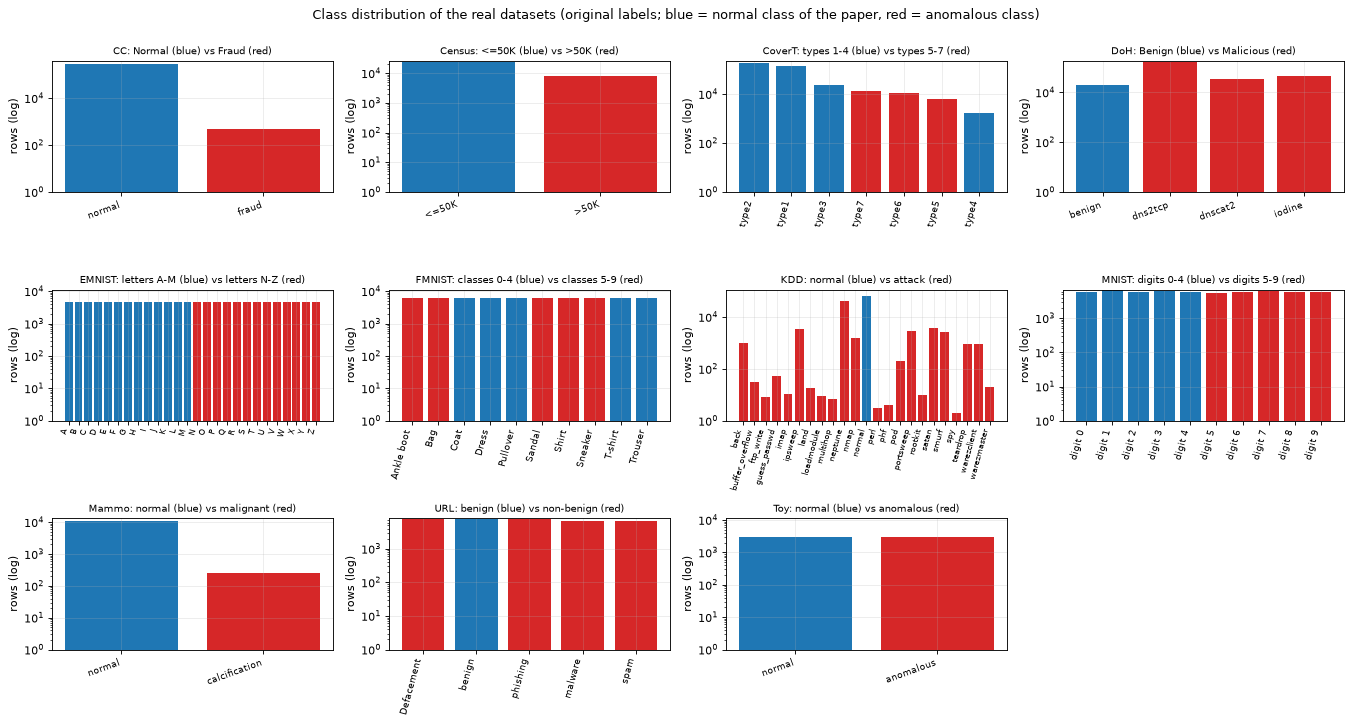

In [6]:
# ---- (a) shape, features, original labels and class counts of every dataset actually used ----
for name in DATASETS:
    p = POOLS[name]; cn, ca = PAPER_CLASSES[name]
    print(f"[{name}] source: {p['source']}")
    print(f"   full data: {p['n_rows_loaded']} rows x {p['n_features']} numeric features after encoding   |  paper classes: normal = {cn}, anomalous = {ca}")
    fn = p["feature_names"]; print("   features:", ", ".join(map(str, fn[:8])) + (f", ... ({len(fn) - 8} more)" if len(fn) > 8 else ""))
    cc = pd.Series(p["class_counts"])
    print("   original label values and counts:", ", ".join(f"{k}: {v}" for k, v in cc.items()) if len(cc) <= 12 else
          f"{len(cc)} labels, from {cc.index[0]} ({cc.iloc[0]}) to {cc.index[-1]} ({cc.iloc[-1]})")
    print(f"   cached pool used for the draws: {len(p['X_normal'])} normal + {len(p['X_anomalous'])} anomalous rows\n")

# ---- (b) bar chart of the real classes ----
def label_sets(name):
    p = POOLS[name]; return set(map(str, np.unique(p["y_normal"]))), set(map(str, np.unique(p["y_anomalous"])))
fig, axes = plt.subplots(3, 4, figsize=(17, 9)); axes = axes.ravel()
for ax, name in zip(axes, DATASETS):
    cc = pd.Series(POOLS[name]["class_counts"]); cc.index = cc.index.map(str); ln, la = label_sets(name)
    cc = cc.sort_index() if len(cc) > 8 else cc
    ax.bar(range(len(cc)), cc.values, color=["#1f77b4" if k in ln else "#d62728" for k in cc.index])
    ax.set_xticks(range(len(cc))); ax.set_xticklabels(cc.index, rotation=75 if len(cc) > 4 else 20, ha="right", fontsize=7 if len(cc) > 12 else 8)
    ax.set_yscale("log"); ax.set_ylim(bottom=1); ax.set_title(f"{name}: {PAPER_CLASSES[name][0]} (blue) vs {PAPER_CLASSES[name][1]} (red)", fontsize=9); ax.set_ylabel("rows (log)")
for ax in axes[len(DATASETS):]: ax.axis("off")
plt.suptitle("Class distribution of the real datasets (original labels; blue = normal class of the paper, red = anomalous class)", y=1.0); plt.tight_layout(); plt.show()


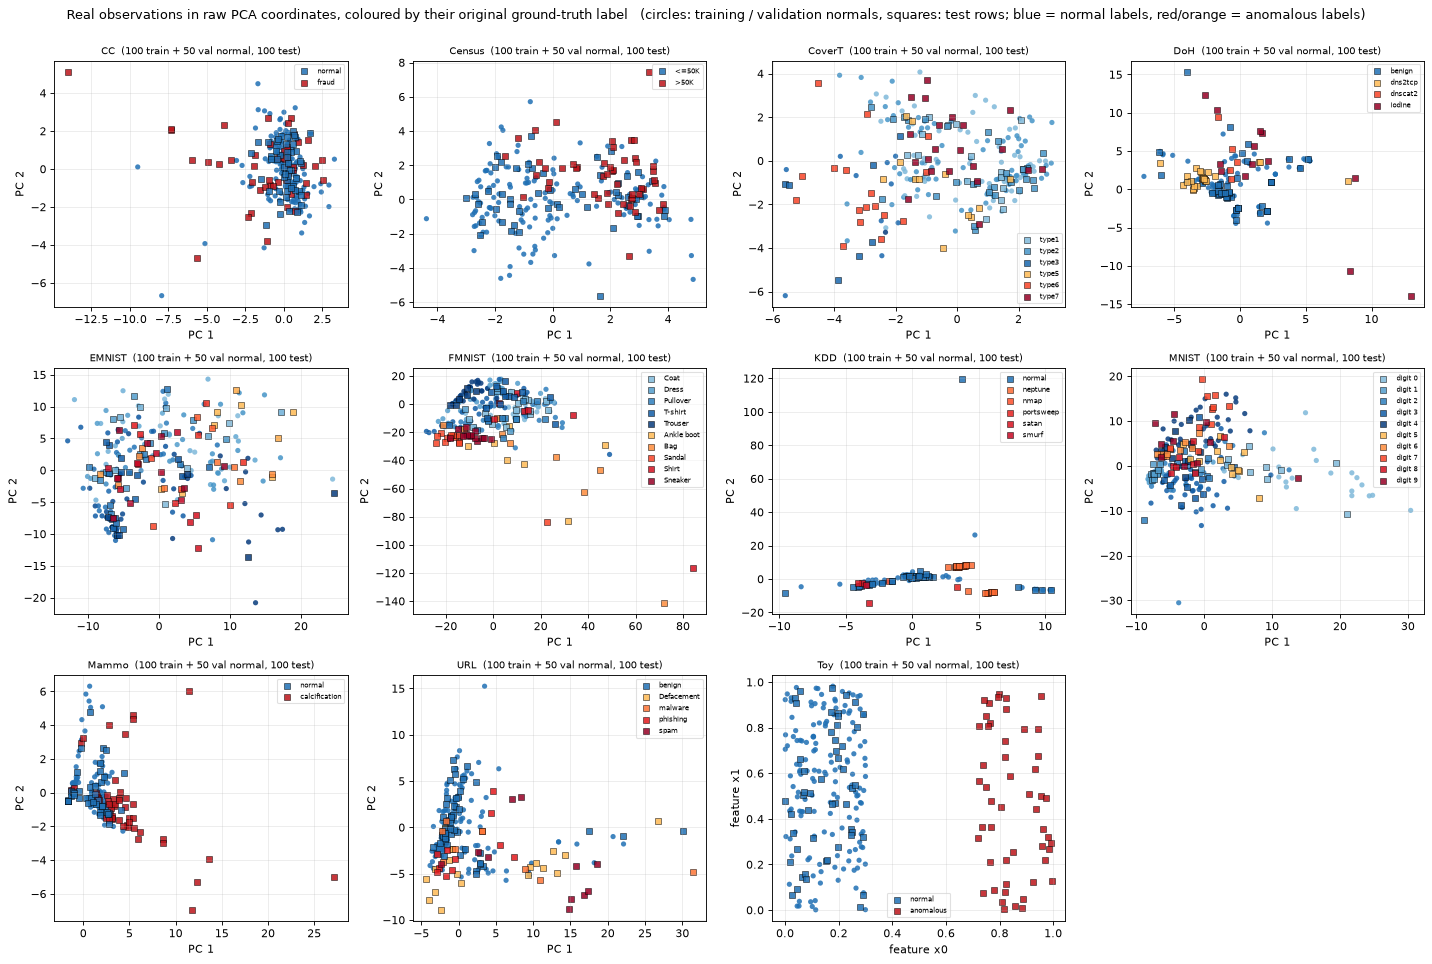

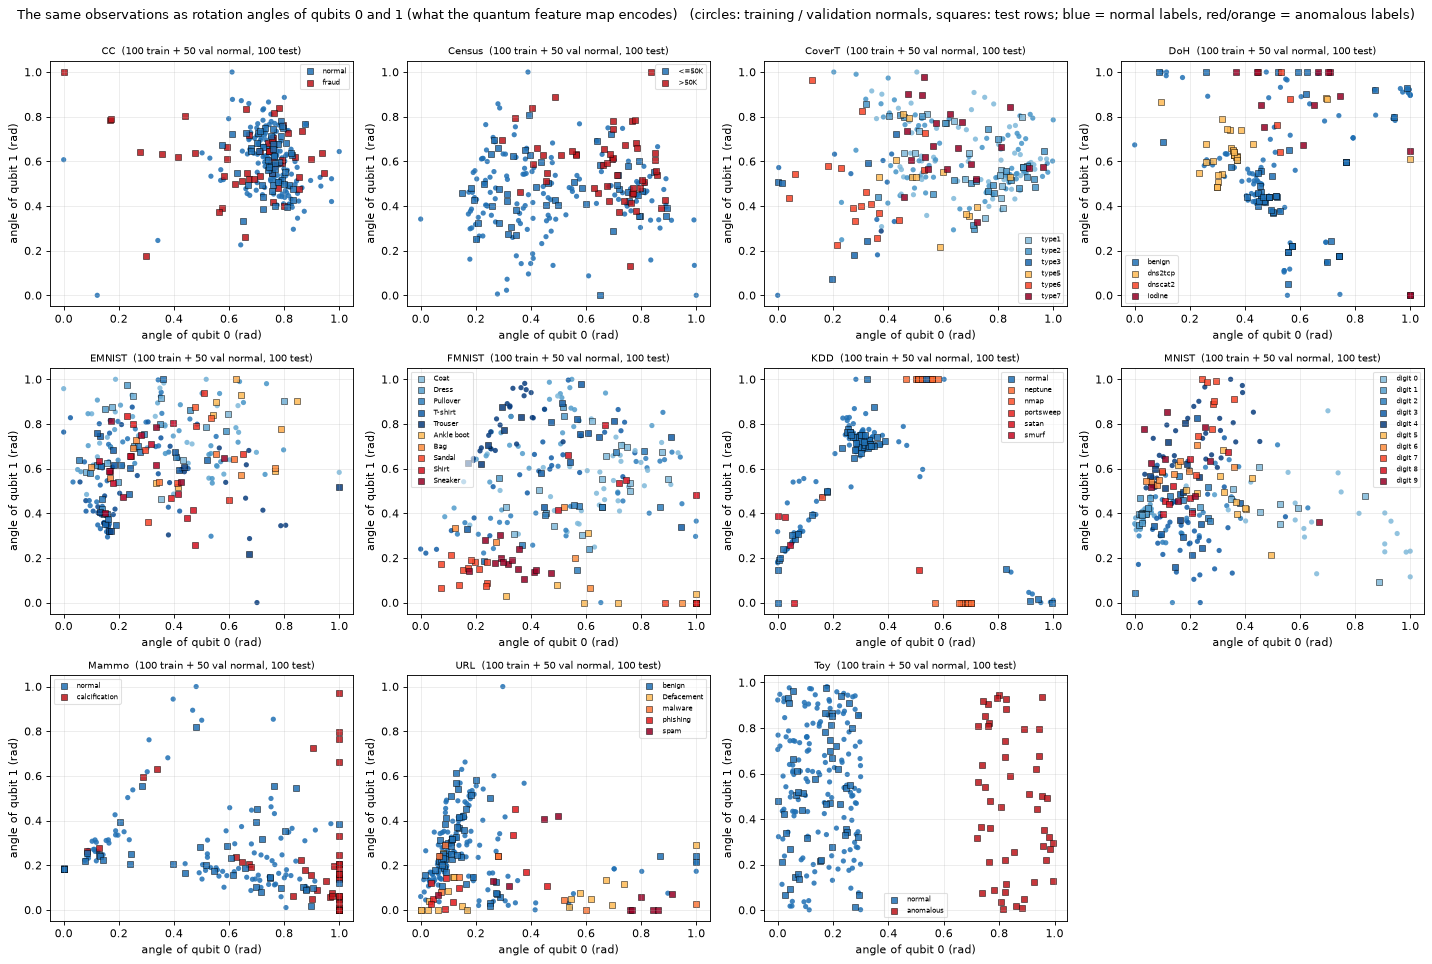

In [7]:
def colour_map(name, labels):
    """Normal labels get blues, anomalous labels get reds/oranges, so the multi-class structure (digit, attack family, tool, ...) stays visible."""
    ln, la = label_sets(name); ln, la = sorted(ln), sorted(la)
    cm = {}
    for i, k in enumerate(ln): cm[k] = plt.cm.Blues(0.45 + 0.5 * i / max(1, len(ln) - 1)) if len(ln) > 1 else plt.cm.Blues(0.75)
    for i, k in enumerate(la): cm[k] = plt.cm.YlOrRd(0.35 + 0.6 * i / max(1, len(la) - 1)) if len(la) > 1 else plt.cm.Reds(0.8)
    return cm, ln, la

def scatter_panels(coord_fn, title, xlab, ylab):
    fig, axes = plt.subplots(3, 4, figsize=(18, 12)); axes = axes.ravel()
    for ax, name in zip(axes, DATASETS):
        d = get_prep(name, 0); cm, ln, la = colour_map(name, None)
        for split, marker, size in [("train", "o", 22), ("val", "o", 22), ("test", "s", 30)]:
            C = coord_fn(d, split); L = np.asarray(d["l_" + split]).astype(str)
            for k in np.unique(L):
                m = L == k
                ax.scatter(C[m, 0], C[m, 1], s=size, marker=marker, color=cm[k], edgecolor="k" if split == "test" else "none", lw=0.5,
                           alpha=0.85, label=f"{k}" if split == "test" or (split == "train" and k in ln) else None)
        h, l = ax.get_legend_handles_labels(); seen = dict(zip(l, h))
        if len(seen) <= 10: ax.legend(seen.values(), seen.keys(), fontsize=6.5, loc="best", framealpha=0.6)
        ax.set_title(f"{name}  ({len(d['l_train'])} train + {len(d['l_val'])} val normal, {len(d['l_test'])} test)", fontsize=9)
        ax.set_xlabel(xlab(name)); ax.set_ylabel(ylab(name))
    for ax in axes[len(DATASETS):]: ax.axis("off")
    plt.suptitle(title + "   (circles: training / validation normals, squares: test rows; blue = normal labels, red/orange = anomalous labels)", y=1.0)
    plt.tight_layout(); plt.show()

# raw coordinates: first two principal components, scaler and PCA fitted on the 100 normal training rows only (Toy: its first two raw features)
scatter_panels(lambda d, s: d["P_" + s][:, :2], "Real observations in raw PCA coordinates, coloured by their original ground-truth label",
               lambda n: "PC 1" if n != "Toy" else "feature x0", lambda n: "PC 2" if n != "Toy" else "feature x1")
# the same points as the rotation angles the circuit receives: RX(a), RZ(a) with a = ANGLE_SCALE * feature, features min-max scaled to [0, 1] on the training split
scatter_panels(lambda d, s: ANGLE_SCALE * d["Z_" + s][:, :2], "The same observations as rotation angles of qubits 0 and 1 (what the quantum feature map encodes)",
               lambda n: "angle of qubit 0 (rad)", lambda n: "angle of qubit 1 (rad)")


## Quantum Circuit Architecture

The model has **one** quantum architecture: the five-qubit inversion-test circuit of Figure 1 of the paper. For one entry of the kernel matrix it loads a sample $x_j$ with $U$ (an `RX` layer, an `RZ` layer and four neighbouring `IsingZZ` gates whose angle is the product of two features), then undoes a second sample $x_i$ with $U^\dagger$ and measures all qubits; the kernel entry is the probability of the outcome `00000`. The paper does not say in which order `RZ` and `RX` act, how the `IsingZZ` gates are arranged, or whether the angles are scaled; the choices made here are listed in the table at the top and marked `# CHOICE:` in the code. The drawing is produced by `qml.draw_mpl` on the very QNode that is evaluated (with the rows of the DoH dataset), once noise-free (`default.qubit`) and once with a depolarizing channel after every gate (`default.mixed`), the form used in the noise study. The kernel has no trainable circuit parameters: the only trained object is the classical SVR on top of the kernel matrix.

In [8]:
wires = list(range(N_QUBITS))

def pl_noise(noise, ws):
    """The same noise insertion rule as in the fast simulator: after every gate, on the wires the gate touched."""
    if noise is None: return
    kind, p = noise
    for w in ws:
        if   kind == "bit_flip":          qml.BitFlip(p, wires=w)
        elif kind == "phase_flip":        qml.PhaseFlip(p, wires=w)
        elif kind == "depolarizing":      qml.DepolarizingChannel(p, wires=w)
        elif kind == "phase_damping":     qml.PhaseDamping(p, wires=w)
        elif kind == "amplitude_damping": qml.AmplitudeDamping(p, wires=w)
        elif kind == "miscalibration":    qml.RX(p, wires=w)

def embed_pl(x, noise=None):
    """U(x): RX layer, RZ layer, IsingZZ(x_q * x_{q+1}) on neighbouring qubits (paper Section 3.1)."""
    for q in wires:                qml.RX(ANGLE_SCALE * x[q], wires=q); pl_noise(noise, [q])
    for q in wires:                qml.RZ(ANGLE_SCALE * x[q], wires=q); pl_noise(noise, [q])
    for q in wires[:-1]:           qml.IsingZZ(ANGLE_SCALE ** 2 * x[q] * x[q + 1], wires=[q, q + 1]); pl_noise(noise, [q, q + 1])

def embed_pl_inverse(x, noise=None):
    """U^dagger(x): the same gates with negated angles, in reverse order."""
    for q in reversed(wires[:-1]): qml.IsingZZ(-ANGLE_SCALE ** 2 * x[q] * x[q + 1], wires=[q, q + 1]); pl_noise(noise, [q, q + 1])
    for q in reversed(wires):      qml.RZ(-ANGLE_SCALE * x[q], wires=q); pl_noise(noise, [q])
    for q in reversed(wires):      qml.RX(-ANGLE_SCALE * x[q], wires=q); pl_noise(noise, [q])

dev_pure  = qml.device("default.qubit", wires=N_QUBITS)
dev_mixed = qml.device("default.mixed", wires=N_QUBITS)

@qml.qnode(dev_pure)
def kernel_qnode(x_i, x_j):
    """Noiseless inversion test: kernel = probability of the all-zero outcome after U(x_j) then U^dagger(x_i)  (paper Eq. 2, Figure 1)."""
    embed_pl(x_j); embed_pl_inverse(x_i)
    return qml.probs(wires=wires)

def make_noisy_qnode(noise):
    @qml.qnode(dev_mixed)
    def kernel_noisy(x_i, x_j):
        embed_pl(x_j, noise); embed_pl_inverse(x_i, noise)
        return qml.probs(wires=wires)
    return kernel_noisy


x_i (training row, angles in rad): [0.471 0.426 0.247 0.441 0.449] 
x_j (anomalous test row)           : [0.348 0.658 0.398 0.43  0.631]


Matplotlib is building the font cache; this may take a moment.


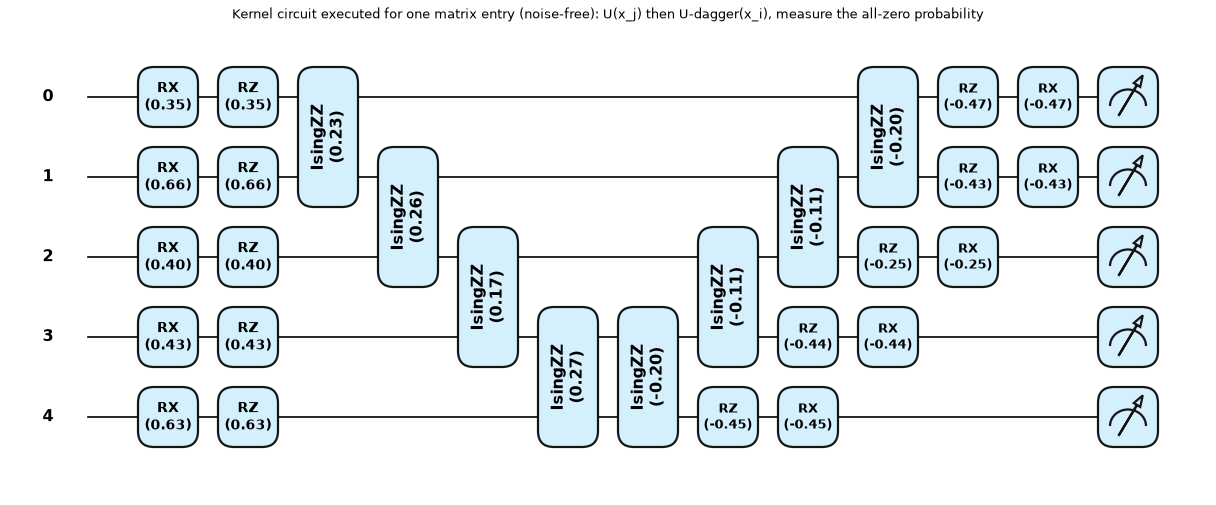

Matplotlib is building the font cache; this may take a moment.


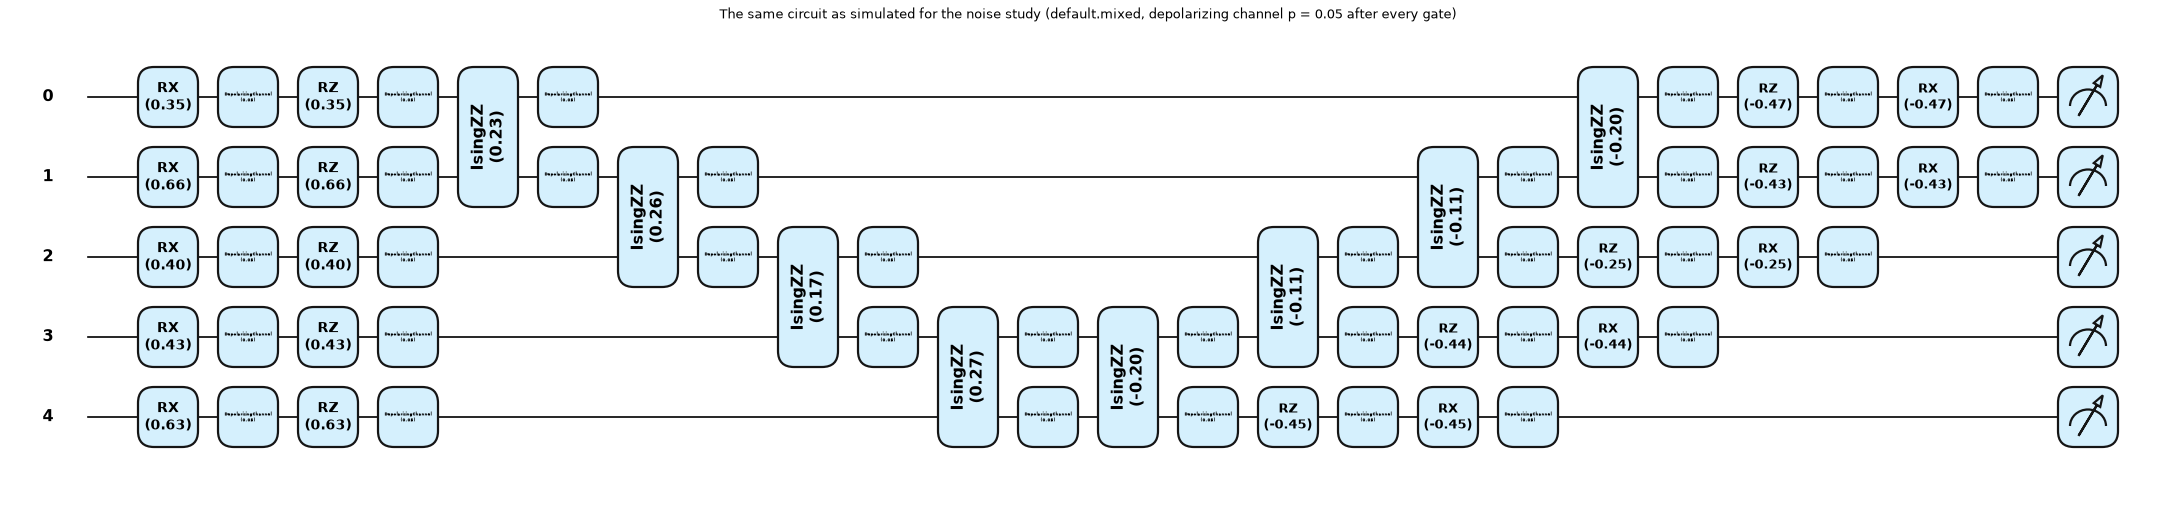

noise-free circuit            : qubits = 5, depth = 12, operations = 28, gate types = {'RX': 10, 'RZ': 10, 'IsingZZ': 8}
noisy circuit (depolarizing)  : qubits = 5, depth = 24, operations = 64, gate types = {'RX': 10, 'DepolarizingChannel': 36, 'RZ': 10, 'IsingZZ': 8}
trainable circuit parameters: 0 (every angle is a data feature; the only trained objects are the classical SVR dual coefficients)


In [9]:
# The two rows come from the real DoH data (draw 0): one training row x_i and one test row x_j, already scaled to angles.
dd = get_prep("DoH", 0); x_i, x_j = dd["Z_train"][0], dd["Z_test"][60]
print("x_i (training row, angles in rad):", np.round(ANGLE_SCALE * x_i, 3), "\nx_j (anomalous test row)           :", np.round(ANGLE_SCALE * x_j, 3))

fig, ax = qml.draw_mpl(kernel_qnode, decimals=2, style="pennylane")(x_i, x_j)
fig.suptitle("Kernel circuit executed for one matrix entry (noise-free): U(x_j) then U-dagger(x_i), measure the all-zero probability", y=1.02)
plt.show()

noisy_demo = make_noisy_qnode(("depolarizing", 0.05))
fig, ax = qml.draw_mpl(noisy_demo, decimals=2, style="pennylane")(x_i, x_j)
fig.suptitle("The same circuit as simulated for the noise study (default.mixed, depolarizing channel p = 0.05 after every gate)", y=1.02)
plt.show()

for label, qn in [("noise-free circuit", kernel_qnode), ("noisy circuit (depolarizing)", noisy_demo)]:
    res = qml.specs(qn)(x_i, x_j)["resources"]
    n_gates = res.num_gates; depth = res.depth
    print(f"{label:30s}: qubits = {len(qn.device.wires)}, depth = {depth}, operations = {n_gates}, gate types = {dict(res.gate_types)}")
print("trainable circuit parameters: 0 (every angle is a data feature; the only trained objects are the classical SVR dual coefficients)")


## 3. Fast exact simulators and their equivalence with PennyLane

Running `default.mixed` for each of the 10,000 + 10,000 + 10,000 kernel entries of one noisy model, for more than 500 noisy models and 11 datasets, would take days. The kernel entry factorises, though: $\kappa(x_i,x_j)=\mathrm{Tr}\big[\,\mathcal{E}_i^\dagger(|0\rangle\langle 0|)\;\rho_j\,\big]$, where $\rho_j$ is the (noisy) density matrix after $U(x_j)$ and $\mathcal{E}_i^\dagger$ is the Heisenberg-picture (adjoint) channel of the noisy $U^\dagger(x_i)$. So we evolve one density matrix and one observable per *row* (batched numpy over all rows), and a whole kernel matrix is a single matrix product. The noise-free kernel has an even simpler statevector form. The cell after the simulator checks both against the PennyLane circuits drawn above, to numerical precision, for all six noise channels. The simulator is exact, the same exactness the paper stresses for `default.mixed` ("the simulations show no error bars because ... computes exact outputs").

In [10]:
n, DIM = N_QUBITS, 2 ** N_QUBITS
I2 = np.eye(2, dtype=complex)
PX = np.array([[0, 1], [1, 0]], dtype=complex); PY = np.array([[0, -1j], [1j, 0]]); PZ = np.diag([1.0, -1.0]).astype(complex)
BITS = (np.arange(DIM)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1       # BITS[k, q] = value of qubit q in basis state k (qubit 0 = most significant)
SIGN = 1 - 2 * BITS                                                          # +1 for |0>, -1 for |1>

def kraus_set(kind, p):
    """Single-qubit Kraus operators of the paper's channels (Section 2.2), strength p."""
    if kind == "bit_flip":          return [np.sqrt(1 - p) * I2, np.sqrt(p) * PX]
    if kind == "phase_flip":        return [np.sqrt(1 - p) * I2, np.sqrt(p) * PZ]
    if kind == "depolarizing":      return [np.sqrt(1 - p) * I2, np.sqrt(p / 3) * PX, np.sqrt(p / 3) * PY, np.sqrt(p / 3) * PZ]
    if kind == "phase_damping":     return [np.diag([1, np.sqrt(1 - p)]).astype(complex), np.diag([0, np.sqrt(p)]).astype(complex)]    # lambda = p
    if kind == "amplitude_damping": return [np.array([[1, 0], [0, np.sqrt(1 - p)]], dtype=complex), np.array([[0, np.sqrt(p)], [0, 0]], dtype=complex)]
    if kind == "miscalibration":    # coherent over-rotation: one Kraus operator, RX(p)   # CHOICE: axis x
        c, s = np.cos(p / 2), np.sin(p / 2); return [np.array([[c, -1j * s], [-1j * s, c]])]
    raise ValueError(kind)

def superop(kraus):
    """A one-qubit channel as a 4x4 matrix acting on vec(rho) (index pairs (x,y) <- (a,b)): rho'[x,y] = sum_ab S[xy,ab] rho[a,b],
    returned together with its adjoint (the Heisenberg-picture map)."""
    S = sum(np.einsum("xa,yb->xyab", K, np.conj(K)) for K in kraus).reshape(4, 4)
    return S, np.conj(S).T

IDENT = (np.eye(4, dtype=complex), np.eye(4, dtype=complex))
def noise_full(noise):
    """noise = None, (kind, p), or ("hardware_like", (p_1q, p_2q)) -> {"1": superoperator after one-qubit gates, "2": after two-qubit gates}."""
    if noise is None: return None
    kind, p = noise
    if kind == "hardware_like":       # CHOICE: depolarizing stand-in for the Ehningen calibration of the paper's Table 1 (not the real device)
        return {"1": superop(kraus_set("depolarizing", p[0])), "2": superop(kraus_set("depolarizing", p[1]))}
    s = superop(kraus_set(kind, p))
    return {"1": s, "2": s}

def rx_super(theta):                   # superoperator of RX(theta) per sample: (N, 4, 4)
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    U = np.stack([np.stack([c, -1j * s], -1), np.stack([-1j * s, c], -1)], -2).astype(complex)
    return np.einsum("nxa,nyb->nxyab", U, np.conj(U)).reshape(len(theta), 4, 4)
def rz_super(theta):                   # superoperator of RZ(theta) per sample: diagonal
    d = np.stack([np.exp(-0.5j * theta), np.exp(0.5j * theta)], -1)
    M = np.zeros((len(theta), 4, 4), dtype=complex)
    M[:, np.arange(4), np.arange(4)] = (d[:, :, None] * np.conj(d)[:, None, :]).reshape(len(theta), 4)
    return M

def circuit_ops(Xs, inverse, nz):
    """Gate list of the kernel half-circuit with the noise channel after EVERY gate on the wires the gate touched.
    Forward U(x):  RX(x_q) for all q, RZ(x_q) for all q, IsingZZ(x_q x_{q+1}) for q = 0..n-2.   Inverse: the adjoint gates in reverse order.
    For speed the RX / noise / RZ / noise sequence of one qubit is multiplied into ONE 4x4 superoperator (gates on different qubits commute)."""
    S1 = nz["1"][0] if nz is not None else IDENT[0]
    ops = []
    zz = lambda a, b, s: ("d", np.exp(-0.5j * s * (Xs[:, a] * Xs[:, b])[:, None] * (SIGN[:, a] * SIGN[:, b])[None, :]))
    def noise_on(qs):
        if nz is not None:
            for q in qs: ops.append(("s", q, nz["2"]))
    if not inverse:
        for q in range(n):     ops.append(("m", q, S1 @ rz_super(Xs[:, q]) @ S1 @ rx_super(Xs[:, q])))          # RX, noise, RZ, noise
        for q in range(n - 1): ops.append(zz(q, q + 1, 1)); noise_on([q, q + 1])
    else:
        for q in reversed(range(n - 1)): ops.append(zz(q, q + 1, -1)); noise_on([q, q + 1])
        for q in reversed(range(n)):     ops.append(("m", q, S1 @ rx_super(-Xs[:, q]) @ S1 @ rz_super(-Xs[:, q])))   # RZ^-1, noise, RX^-1, noise
    return ops

def _six(rho, q):                      # (N, DIM, DIM) -> (N, hi, ket_q, lo, hi', bra_q, lo')
    L, R = 2 ** q, 2 ** (n - q - 1); return rho.reshape(len(rho), L, 2, R, L, 2, R)
def _apply_m(rho, q, M):               # M: (N, 4, 4) per-sample or (4, 4) shared superoperator on qubit q
    a = np.moveaxis(_six(rho, q), (2, 5), (1, 2)); sh = a.shape
    out = (M @ a.reshape(sh[0], 4, -1)).reshape(sh)
    return np.moveaxis(out, (1, 2), (2, 5)).reshape(rho.shape)

def evolve(rho, ops):
    for op in ops:
        if op[0] == "m":   rho = _apply_m(rho, op[1], op[2])
        elif op[0] == "d": g = op[1]; rho = rho * g[:, :, None]; rho *= np.conj(g)[:, None, :]
        else:              rho = _apply_m(rho, op[1], op[2][0])
    return rho
def evolve_adjoint(O, ops):
    for op in reversed(ops):
        if op[0] == "m":   O = _apply_m(O, op[1], np.conj(op[2]).swapaxes(-1, -2))
        elif op[0] == "d": g = op[1]; O = np.conj(g)[:, :, None] * O; O *= g[:, None, :]
        else:              O = _apply_m(O, op[1], op[2][1])
    return O

def states(X, noise=None, scale=None, forward_only=False):
    """Noisy forward density matrices rho_j (after U(x_j)) and Heisenberg observables O_i (adjoint channel of U^dagger(x_i) applied to |0><0|)
    for every row of X. A kernel entry is then Tr(O_i rho_j): the cost is linear (not quadratic) in the number of rows."""
    scale = ANGLE_SCALE if scale is None else scale
    nz = noise_full(noise)
    rho0 = np.zeros((len(X), DIM, DIM), dtype=complex); rho0[:, 0, 0] = 1
    rho = evolve(rho0, circuit_ops(scale * X, False, nz))
    if forward_only: return rho, None
    O0 = np.zeros((len(X), DIM, DIM), dtype=complex); O0[:, 0, 0] = 1
    O = evolve_adjoint(O0, circuit_ops(scale * X, True, nz))
    return rho, O

def _overlap(O, rho):                  # [a, b] = Tr(O_a rho_b), real part
    return (O.reshape(len(O), -1) @ rho.transpose(0, 2, 1).reshape(len(rho), -1).T).real

def dm_kernel(XA, XB, noise=None, scale=None):
    """K[a, b] = P(all zeros) after  U(x_B) (noisy)  followed by  U^dagger(x_A) (noisy), i.e. the inversion-test kernel of Eq. 2."""
    O = states(XA, noise, scale)[1]
    rho = states(XB, noise, scale, forward_only=True)[0]
    return _overlap(O, rho)

def kernel_from_states(sa, sb):
    """Symmetrised kernel (K + K^T)/2 between two sets whose states() are known: with noise the inversion test is not exactly symmetric."""
    return 0.5 * (_overlap(sa[1], sb[0]) + _overlap(sb[1], sa[0]).T)

def test_kernel(s_train, X_query, noise=None):
    """Kernel between query rows and training rows, shape (queries, training): the TRAINING row is the inverse half U^dagger(x_i) and the query row
    the forward half U(x_j), so only one forward evolution of the (possibly adversarial) query set is needed."""
    return _overlap(s_train[1], states(X_query, noise, forward_only=True)[0]).T

def sym_kernel(XA, XB, noise=None):
    return kernel_from_states(states(XA, noise), states(XB, noise))

def phi(X, scale=None):
    """Noiseless feature states (N, DIM): product of RZ(x)RX(x)|0> per qubit, then the IsingZZ phases."""
    scale = ANGLE_SCALE if scale is None else scale
    A = scale * np.atleast_2d(X)
    single = np.stack([np.cos(A / 2) * np.exp(-0.5j * A), -1j * np.sin(A / 2) * np.exp(0.5j * A)], -1)     # (N, n, 2): RZ(x) RX(x) |0>
    psi = np.ones((len(A), 1), dtype=complex)
    for q in range(n):
        psi = (psi[:, :, None] * single[:, q, None, :]).reshape(len(A), -1)
    ph = np.zeros((len(A), DIM))
    for q in range(n - 1):
        ph += (A[:, q] * A[:, q + 1])[:, None] * (SIGN[:, q] * SIGN[:, q + 1])[None, :]
    return psi * np.exp(-0.5j * ph)

def q_kernel(XA, XB, scale=None):
    """Noiseless fidelity kernel |<phi(a)|phi(b)>|^2 (fast statevector path)."""
    return np.abs(np.conj(phi(XA, scale)) @ phi(XB, scale).T) ** 2


In [11]:
# Equivalence checks: the PennyLane circuits (what is drawn above) and the fast simulators (what the sweeps below use) must agree.
d = get_prep("DoH", 0)
XA, XB = d["Z_train"][:4], d["Z_test"][[0, 1, 60, 70]]

K_pl = np.array([[float(kernel_qnode(a, b)[0]) for b in XB] for a in XA])
K_sv = q_kernel(XA, XB)
K_dm = dm_kernel(XA, XB, None)
print("noiseless  |PennyLane - statevector|max =", np.abs(K_pl - K_sv).max(), "| |PennyLane - density-matrix sim|max =", np.abs(K_pl - K_dm).max())
assert np.allclose(K_pl, K_sv, atol=1e-10) and np.allclose(K_pl, K_dm, atol=1e-10)

rows = []
for kind, p in [("bit_flip", 0.1), ("phase_flip", 0.1), ("depolarizing", 0.1), ("phase_damping", 0.3), ("amplitude_damping", 0.2), ("miscalibration", 0.7)]:
    qn = make_noisy_qnode((kind, p))
    K_pl_n = np.array([[float(qn(a, b)[0]) for b in XB[:2]] for a in XA[:2]])
    K_dm_n = dm_kernel(XA[:2], XB[:2], (kind, p))
    err = np.abs(K_pl_n - K_dm_n).max(); rows.append(dict(channel=kind, strength=p, max_abs_diff=err, kernel_noisy=K_dm_n[0, 0], kernel_clean=K_pl[0, 0]))
    assert err < 1e-9, (kind, err)
display(pd.DataFrame(rows))
print("All six noise channels: the fast density-matrix simulator reproduces PennyLane's default.mixed to numerical precision.")


noiseless  |PennyLane - statevector|max = 7.771561172376096e-16 | |PennyLane - density-matrix sim|max = 1.5543122344752192e-15


,channel,strength,max_abs_diff,kernel_noisy,kernel_clean
0,bit_flip,0.1,5.064005e-14,0.083012,0.970937
1,phase_flip,0.1,5.211387e-13,0.691529,0.970937
2,depolarizing,0.1,1.551259e-13,0.142748,0.970937
3,phase_damping,0.3,7.105427e-15,0.718147,0.970937
4,amplitude_damping,0.2,2.320366e-14,0.957256,0.970937
5,miscalibration,0.7,4.857226e-17,0.033179,0.970937


All six noise channels: the fast density-matrix simulator reproduces PennyLane's default.mixed to numerical precision.


## 4. The QSVR and a first look at the noise-free AUC

`QSVR` fits one `SVR(kernel="precomputed")` per input feature with the target equal to the feature itself (reconstruction); the anomaly score of a sample is the mean squared reconstruction error over the five features, and the AUC treats anomalies as the positive class. The cell trains the noise-free model on every dataset (draw 0) and prints the AUC and the average score of each class.

In [12]:
class QSVR:
    """Semi-supervised anomaly detector of Tscharke et al.: one kernel SVR per input feature, trained on normal data only to
    RECONSTRUCT its own input; the anomaly score is the mean squared reconstruction error (Tscharke et al. 2023)."""
    def __init__(self, C=SVR_C, eps=SVR_EPS):
        self.C, self.eps = C, eps
    def fit(self, K, Y):
        m, d = Y.shape
        self.alpha, self.b = np.zeros((d, m)), np.zeros(d)
        for k in range(d):
            s = SVR(kernel="precomputed", C=self.C, epsilon=self.eps).fit(K, Y[:, k])
            self.alpha[k, s.support_] = s.dual_coef_[0]; self.b[k] = s.intercept_[0]
        return self
    def predict(self, Kq):                        # Kq: (queries, training points)
        return Kq @ self.alpha.T + self.b
    def score(self, Kq, Xq):                      # anomaly score = reconstruction MSE
        return ((self.predict(Kq) - Xq) ** 2).mean(axis=1)

def auc(y, s):
    return float(roc_auc_score(y, s))

def fit_eval(Z_train, Z_eval_list, noise=None, targets=None):
    """Train one QSVR (optionally under a noise channel) and return its anomaly scores for every array in Z_eval_list."""
    if noise is None:
        K = q_kernel(Z_train, Z_train); Kq = [q_kernel(Z, Z_train) for Z in Z_eval_list]
    else:
        K = sym_kernel(Z_train, Z_train, noise); Kq = [sym_kernel(Z, Z_train, noise) for Z in Z_eval_list]
    model = QSVR().fit(K, Z_train if targets is None else targets)
    return model, [model.score(k, Z) for k, Z in zip(Kq, Z_eval_list)], Kq

# ---- first look: noiseless QSVR on every dataset, data draw 0 ----
t0 = time.time(); rows = []
for name in DATASETS:
    d = get_prep(name, 0)
    model, (s_te,), _ = fit_eval(d["Z_train"], [d["Z_test"]])
    rows.append(dict(dataset=name, AUC=auc(d["y_test"], s_te), mean_score_normal=s_te[d["y_test"] == 0].mean(), mean_score_anomalous=s_te[d["y_test"] == 1].mean()))
first_look = pd.DataFrame(rows).set_index("dataset")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(first_look)
print(f"mean AUC over the {len(DATASETS)} datasets: {first_look['AUC'].mean():.3f}   ({time.time()-t0:.1f} s)")


,AUC,mean_score_normal,mean_score_anomalous
dataset,,,
CC,0.729,0.000235,0.00344
Census,0.57,0.000124,0.00054
CoverT,0.684,0.000355,0.000386
DoH,0.745,0.000575,0.00249
EMNIST,0.609,0.000452,0.000366
FMNIST,0.91,0.000883,0.00716
KDD,0.968,0.00334,0.0696
MNIST,0.546,0.000358,0.00232
Mammo,0.862,0.00036,0.00776


mean AUC over the 11 datasets: 0.768   (0.6 s)


## 5. Classical competitors on the same five features

The paper compares against a simulated QSVR, a quantum autoencoder, a classical SVR (CSVR) and a classical autoencoder (CAE). Here the same five angle features feed: an RBF-kernel SVR trained like the QSVR (CSVR), a small 5-3-5 autoencoder (CAE), a one-class SVM and an isolation forest, all trained on normal rows only. As an *upper reference* that is not allowed in the semi-supervised setting, a random forest and an RBF-`SVC` are trained on 100 normal + 100 **labelled anomalous** rows. The quantum autoencoder is not implemented (it needs a trained variational circuit the paper only cites). Over `N_SEEDS` data draws the table shows mean AUC.

In [13]:
def all_model_scores(d):
    """Anomaly scores of the QSVR and of the classical competitors, all on the SAME five angle features (higher = more anomalous)."""
    Ztr, Zte = d["Z_train"], d["Z_test"]; out = {}
    _, (s,), _ = fit_eval(Ztr, [Zte]); out["QSVR (noiseless)"] = s
    gamma = 1.0 / (N_QUBITS * Ztr.var() + 1e-12)                                    # CHOICE: scikit-learn's gamma="scale" rule
    m = QSVR().fit(rbf_kernel(Ztr, Ztr, gamma=gamma), Ztr)
    out["CSVR (RBF kernel)"] = m.score(rbf_kernel(Zte, Ztr, gamma=gamma), Zte)
    ae = MLPRegressor(hidden_layer_sizes=(3,), activation="tanh", solver="lbfgs", max_iter=3000, random_state=SEED).fit(Ztr, Ztr)   # CHOICE: 5-3-5 bottleneck
    out["CAE (5-3-5 MLP)"] = ((ae.predict(Zte) - Zte) ** 2).mean(axis=1)
    out["One-class SVM (RBF)"] = -OneClassSVM(gamma="scale", nu=0.1).fit(Ztr).decision_function(Zte)     # CHOICE: nu = 0.1
    out["Isolation Forest"] = -IsolationForest(n_estimators=200, random_state=SEED).fit(Ztr).score_samples(Zte)
    Xs = np.vstack([d["Z_sup_n"], d["Z_sup_a"]]); ys = np.r_[np.zeros(len(d["Z_sup_n"])), np.ones(len(d["Z_sup_a"]))]
    out["RandomForest (supervised, sees anomalies)"] = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xs, ys).predict_proba(Zte)[:, 1]
    out["SVC rbf (supervised, sees anomalies)"] = SVC(kernel="rbf").fit(Xs, ys).decision_function(Zte)
    return out

t0 = time.time(); acc = {}
for name in DATASETS:
    for draw in range(N_SEEDS):
        d = get_prep(name, draw)
        for mname, s in all_model_scores(d).items():
            acc.setdefault(mname, {}).setdefault(name, []).append(auc(d["y_test"], s))
BASE_MEAN = pd.DataFrame({m: {n: np.mean(v) for n, v in dd.items()} for m, dd in acc.items()}).loc[DATASETS]
BASE_STD  = pd.DataFrame({m: {n: np.std(v) for n, v in dd.items()} for m, dd in acc.items()}).loc[DATASETS]
QSVR_AUC = BASE_MEAN["QSVR (noiseless)"]              # reused below as the "no retraining, no noise, no attack" reference
tab = BASE_MEAN.copy(); tab.loc["MEAN"] = tab.mean()
display(tab.round(3))
if N_SEEDS > 1:
    print(f"Std over the {N_SEEDS} independent data draws (mean over datasets of the per-dataset std):")
    display(BASE_STD.mean().round(3).to_frame("avg std").T)
print(f"{time.time()-t0:.0f} s")


,QSVR (noiseless),CSVR (RBF kernel),CAE (5-3-5 MLP),One-class SVM (RBF),Isolation Forest,"RandomForest (supervised, sees anomalies)","SVC rbf (supervised, sees anomalies)"
CC,0.841,0.851,0.763,0.847,0.855,0.914,0.920
Census,0.568,0.602,0.650,0.602,0.670,0.828,0.827
CoverT,0.716,0.719,0.607,0.562,0.717,0.751,0.792
DoH,0.654,0.819,0.723,0.607,0.741,0.944,0.920
EMNIST,0.555,0.553,0.514,0.362,0.504,0.655,0.661
FMNIST,0.914,0.911,0.839,0.862,0.883,0.949,0.913
KDD,0.968,0.965,0.936,0.886,0.959,0.993,0.993
MNIST,0.558,0.572,0.452,0.343,0.496,0.838,0.827
Mammo,0.865,0.861,0.761,0.867,0.831,0.910,0.909
URL,0.822,0.863,0.743,0.852,0.819,0.902,0.889


Std over the 3 independent data draws (mean over datasets of the per-dataset std):


,QSVR (noiseless),CSVR (RBF kernel),CAE (5-3-5 MLP),One-class SVM (RBF),Isolation Forest,"RandomForest (supervised, sees anomalies)","SVC rbf (supervised, sees anomalies)"
avg std,0.033,0.028,0.036,0.039,0.04,0.018,0.016


177 s


## 6. The hardware split in simulation

The paper's hardware benchmark used 30 normal training rows and 50 test rows. We cannot run IBM Ehningen, so this cell shows (a) the noise-free simulation of exactly that split and (b) the same split with a **depolarizing stand-in** whose strengths are taken from the paper's Table 1 (single-qubit error 0.025 %, two-qubit gate error 0.7 % per CNOT, one `IsingZZ` = two CNOTs). The stand-in ignores readout error, decoherence, crosstalk and error mitigation, so it is *not* a prediction of the device.

In [14]:
# The paper's hardware split (30 normal training rows, 50 test rows) simulated noise-free, plus a calibration-informed depolarizing stand-in.
# This is NOT the paper's IBM Ehningen run (no hardware access here); it only shows what the same small split gives in simulation.
HW_NOISE = ("hardware_like", (0.00025, 0.014))     # CHOICE: Table 1 single-qubit error 0.025 %; one IsingZZ = 2 CNOTs at 0.7 % each -> 1.4 % per qubit

t0 = time.time(); rows = []
for name in DATASETS:
    for draw in range(N_SEEDS):
        d = get_prep(name, draw, hw=True); Ztr, Zte, y = d["Z_train"], d["Z_test"], d["y_test"]
        m = QSVR().fit(q_kernel(Ztr, Ztr), Ztr); a_sim = auc(y, m.score(q_kernel(Zte, Ztr), Zte))
        s_tr = states(Ztr, HW_NOISE); mn = QSVR().fit(kernel_from_states(s_tr, s_tr), Ztr); a_hw = auc(y, mn.score(test_kernel(s_tr, Zte, HW_NOISE), Zte))
        rows.append(dict(dataset=name, draw=draw, AUC_simulated_30_50=a_sim, AUC_hardware_like_noise=a_hw))
HW = pd.DataFrame(rows).groupby("dataset").mean(numeric_only=True).drop(columns="draw").loc[DATASETS]
HW.loc["MEAN"] = HW.mean(); display(HW.round(3))
print(f"mean drop caused by the stand-in noise: {HW.loc['MEAN','AUC_simulated_30_50'] - HW.loc['MEAN','AUC_hardware_like_noise']:+.3f} AUC  ({time.time()-t0:.0f} s)")
print("Paper (Section 5): hardware 0.72 vs noise-free simulation 0.76, i.e. a drop of 0.04. The paper's hardware numbers themselves cannot be reproduced here.")


,AUC_simulated_30_50,AUC_hardware_like_noise
dataset,,
CC,0.805,0.815
Census,0.597,0.618
CoverT,0.628,0.616
DoH,0.772,0.766
EMNIST,0.673,0.677
FMNIST,0.893,0.891
KDD,0.959,0.967
MNIST,0.553,0.559
Mammo,0.833,0.840


mean drop caused by the stand-in noise: -0.004 AUC  (10 s)
Paper (Section 5): hardware 0.72 vs noise-free simulation 0.76, i.e. a drop of 0.04. The paper's hardware numbers themselves cannot be reproduced here.


## 7. PGD attacks on the noise-free model

The attacker knows the trained model (white box). Its loss is the model's error *on the true label*: for a normal row the reconstruction error is pushed **up** (a false alarm), for an anomalous row it is pushed **down** (a missed attack). One step is $x\leftarrow \Pi\big(x+\alpha\,\mathrm{sign}\nabla_x s(x)\big)$ with $\alpha=\epsilon/n$, projected onto the L-infinity ball of radius $\epsilon$ around the original row and onto the input range [0, 1] (paper Eq. 14, Table 2). The anomaly score $s(x)$ is differentiable in $x$ because the kernel is; its gradient is computed with central finite differences on the statevector kernel (all 100 rows at once), and the next cell verifies it against PennyLane's automatic differentiation of the real circuit. The last cell of this section redraws Figure 4.

eps,0.000,0.005,0.010,0.020,0.050,0.100,0.200,0.300,0.400,0.500
dataset,,,,,,,,,,
CC,0.841,0.805,0.761,0.676,0.427,0.158,0.032,0.001,0.000,0.0
Census,0.568,0.471,0.390,0.261,0.090,0.025,0.011,0.000,0.000,0.0
CoverT,0.716,0.647,0.577,0.443,0.224,0.060,0.001,0.000,0.000,0.0
DoH,0.654,0.550,0.473,0.351,0.218,0.088,0.011,0.000,0.000,0.0
EMNIST,0.555,0.477,0.400,0.256,0.066,0.002,0.000,0.000,0.000,0.0
FMNIST,0.914,0.893,0.868,0.820,0.708,0.425,0.108,0.010,0.000,0.0
KDD,0.968,0.959,0.934,0.916,0.810,0.550,0.231,0.009,0.000,0.0
MNIST,0.558,0.460,0.371,0.237,0.086,0.039,0.005,0.000,0.000,0.0
Mammo,0.865,0.834,0.804,0.716,0.484,0.199,0.016,0.000,0.000,0.0


largest L-inf perturbation produced: 0.500   (553 s)


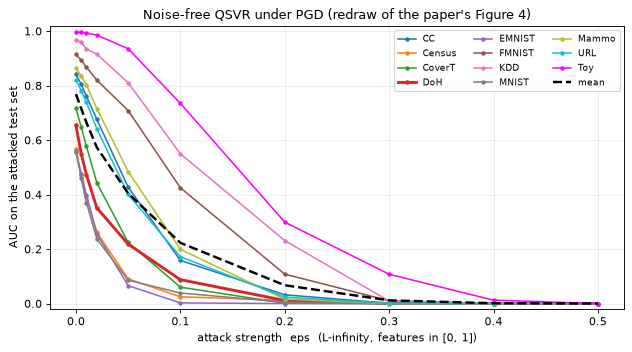

In [15]:
def attack_parts(model, Z_train):
    """Everything the white-box attacker needs from a trained noiseless QSVR: support states and dual coefficients."""
    return dict(Phi=phi(Z_train), alpha=model.alpha, b=model.b)

def score_noiseless(Xq, M):
    Kq = np.abs(np.conj(phi(Xq)) @ M["Phi"].T) ** 2
    return (((Kq @ M["alpha"].T + M["b"]) - Xq) ** 2).mean(axis=1)

def grad_sign_score(X, M, h=1e-5):
    """Gradient of the reconstruction error w.r.t. the five inputs (central finite differences, all samples at once).
    Only the SIGN is used by PGD, and section 6 checks it against PennyLane's automatic differentiation."""
    g = np.zeros_like(X)
    for k in range(X.shape[1]):
        Xp, Xm = X.copy(), X.copy(); Xp[:, k] += h; Xm[:, k] -= h
        g[:, k] = (score_noiseless(Xp, M) - score_noiseless(Xm, M)) / (2 * h)
    return g

def pgd(Z, y, M, eps, n_iter=None):
    """Untargeted L-infinity PGD (paper Eq. 14, Table 2: alpha = eps / n, no random start). The loss is the model's own error on the true label:
    normal samples are pushed towards a HIGH reconstruction error (false alarm), anomalous samples towards a LOW one (missed attack)."""
    n_iter = PGD_ITERS if n_iter is None else n_iter
    if eps == 0: return Z.copy()
    direction = np.where(y == 0, 1.0, -1.0)[:, None]; step = eps / n_iter; X = Z.copy()
    for _ in range(n_iter):
        X = X + step * direction * np.sign(grad_sign_score(X, M))
        X = np.clip(np.clip(X, Z - eps, Z + eps), 0.0, 1.0)             # project on the eps-ball and on the normalised input range
    return X

ADV = {}        # (dataset, draw, eps) -> adversarial test set crafted against the noiseless model
MODEL0 = {}     # (dataset, draw) -> trained noiseless QSVR
def clean_model(name, draw):
    if (name, draw) not in MODEL0:
        d = get_prep(name, draw); MODEL0[(name, draw)] = fit_eval(d["Z_train"], [d["Z_test"]])[0]
    return MODEL0[(name, draw)]
def adv_set(name, draw, eps):
    if (name, draw, eps) not in ADV:
        d = get_prep(name, draw); M = attack_parts(clean_model(name, draw), d["Z_train"])
        ADV[(name, draw, eps)] = pgd(d["Z_test"], d["y_test"], M, eps)
    return ADV[(name, draw, eps)]

t0 = time.time(); rows = []
for name in DATASETS:
    for draw in range(N_SEEDS):
        d = get_prep(name, draw); M = attack_parts(clean_model(name, draw), d["Z_train"])
        for eps in sorted(set(EPS_CURVE) | set(EPS_ATTACK)):
            Zadv = adv_set(name, draw, eps)
            rows.append(dict(dataset=name, draw=draw, eps=eps, AUC=auc(d["y_test"], score_noiseless(Zadv, M)),
                             linf=float(np.abs(Zadv - d["Z_test"]).max())))
ADV_CURVE = pd.DataFrame(rows)
curve = ADV_CURVE.groupby(["dataset", "eps"])["AUC"].mean().unstack("eps").loc[DATASETS]
curve.loc["MEAN"] = curve.mean(); display(curve.round(3))
assert ADV_CURVE["linf"].max() <= max(EPS_CURVE) + 1e-9, "perturbation left the eps-ball"
print(f"largest L-inf perturbation produced: {ADV_CURVE['linf'].max():.3f}   ({time.time()-t0:.0f} s)")

# Figure 4 of the paper: AUC versus attack strength for the noise-free model
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in DATASETS:
    ax.plot(curve.columns, curve.loc[name].to_numpy(), marker="o", ms=3, label=name, color=DS_COLORS[name], lw=1.4 if name != "DoH" else 2.6)
ax.plot(curve.columns, curve.loc["MEAN"].to_numpy(), "k--", lw=2.2, label="mean")
ax.set_xlabel("attack strength  eps  (L-infinity, features in [0, 1])"); ax.set_ylabel("AUC on the attacked test set")
ax.set_title("Noise-free QSVR under PGD (redraw of the paper's Figure 4)"); ax.legend(ncol=3, fontsize=8); ax.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()


In [16]:
# Check of the attack gradient: finite differences (used in the sweeps) against PennyLane automatic differentiation of the real circuit.
from pennylane import numpy as pnp
d = get_prep("KDD", 0); model = clean_model("KDD", 0); M = attack_parts(model, d["Z_train"])
Xq = d["Z_test"][[70]]                       # one real anomalous test row, differentiated through all 100 support circuits
g_fd = grad_sign_score(Xq, M)

def kernel_grad_pl(x_support, x_query):
    f = lambda xq: kernel_qnode(pnp.array(x_support, requires_grad=False), xq)[0]
    return np.asarray(qml.grad(f)(pnp.array(x_query, requires_grad=True)))

g_ad = np.zeros_like(Xq)
for r_i, x in enumerate(Xq):
    K_row = q_kernel(x[None, :], d["Z_train"])[0]
    pred = M["alpha"] @ K_row + M["b"]
    dK = np.stack([kernel_grad_pl(xs, x) for xs in d["Z_train"]])            # (n_train, 5): d k(x_s, x) / dx
    # score = mean_k (pred_k - x_k)^2  ->  grad_j = (2/5) * sum_k (pred_k - x_k) * (sum_s alpha_ks dK_sj - delta_kj)
    dpred = np.einsum("ks,sj->kj", M["alpha"], dK)
    g_ad[r_i] = (2 / N_QUBITS) * ((pred - x)[:, None] * (dpred - np.eye(N_QUBITS))).sum(axis=0)
print("finite-difference gradient :", np.round(g_fd, 6).tolist())
print("autodiff gradient (PennyLane):", np.round(g_ad, 6).tolist())
print("max relative difference:", float(np.max(np.abs(g_fd - g_ad) / (np.abs(g_ad) + 1e-12))), "| signs identical:", bool(np.all(np.sign(g_fd) == np.sign(g_ad))))
assert np.allclose(g_fd, g_ad, rtol=1e-3, atol=1e-9) and np.all(np.sign(g_fd) == np.sign(g_ad))


finite-difference gradient : [[0.069967, 0.070257, -0.215735, 0.015534, 0.252963]]
autodiff gradient (PennyLane): [[0.069967, 0.070257, -0.215735, 0.015534, 0.252963]]
max relative difference: 2.1653923319554996e-09 | signs identical: True


## 8. Influence of quantum noise (with and without attack)

For every dataset the cell trains one QSVR per noise setting (five incoherent channels x the paper's seven probabilities, plus the coherent miscalibration on a 21-point grid, plus the noise-free reference) and evaluates it twice: on the clean test set and on the PGD test set of strength $\epsilon=0.1$ that was crafted against the **noise-free** model (the attack is *transferred*, as in the paper). The kernel of every noisy model is the exact density-matrix result.

In [17]:
MISCAL_GRID = np.linspace(0.0, 2 * np.pi, MISCAL_STEPS + 1)         # paper: 20 linear steps between 0 and 2*pi (21 grid points)
NOISE_LIST = [("none", 0.0)] + [(k, p) for k in NOISE_TYPES for p in NOISE_PROBS] + [("miscalibration", float(p)) for p in MISCAL_GRID]
print(f"{len(NOISE_LIST)-1} noisy models per dataset and data draw  ->  {(len(NOISE_LIST)-1) * len(DATASETS) * N_SEEDS_NOISE} noisy models in total "
      f"(paper: 'over 500 noisy models')")

def noisy_study(name, draw, eps=EPS_NOISY):
    """For one dataset and data draw: train one QSVR per noise setting; test on the clean test set and on the PGD set (crafted against the
    NOISE-FREE model, then transferred, as in the paper's Section 3.4)."""
    d = get_prep(name, draw); Ztr, Zte, y = d["Z_train"], d["Z_test"], d["y_test"]; Zadv = adv_set(name, draw, eps)
    rows = []
    for kind, p in NOISE_LIST:
        noise = None if kind == "none" else (kind, p)
        if noise:
            s_tr = states(Ztr, noise)                                                            # 4 density-matrix evolutions per noisy model
            K, Kc, Ka = kernel_from_states(s_tr, s_tr), test_kernel(s_tr, Zte, noise), test_kernel(s_tr, Zadv, noise)
        else:
            K, Kc, Ka = q_kernel(Ztr, Ztr), q_kernel(Zte, Ztr), q_kernel(Zadv, Ztr)
        model = QSVR().fit(K, Ztr)
        rows.append(dict(dataset=name, draw=draw, noise=kind, p=p, AUC_clean=auc(y, model.score(Kc, Zte)), AUC_adv=auc(y, model.score(Ka, Zadv)),
                         kernel_mean_adv_normal=float(Ka[y == 0].mean()), kernel_mean_adv_anom=float(Ka[y == 1].mean())))
    return rows

t0 = time.time(); allrows = []
for name in DATASETS:
    for draw in range(N_SEEDS_NOISE):
        allrows += noisy_study(name, draw)
    print(f"  {name:7s} done  ({time.time()-t0:.0f} s)")
NOISE_DF = pd.DataFrame(allrows)
NOISE_MEAN = NOISE_DF.groupby(["dataset", "noise", "p"], as_index=False)[["AUC_clean", "AUC_adv", "kernel_mean_adv_normal", "kernel_mean_adv_anom"]].mean()
print("total noise-study time: %.0f s" % (time.time() - t0))
display(NOISE_MEAN.groupby("noise")[["AUC_clean", "AUC_adv"]].mean().round(3))


56 noisy models per dataset and data draw  ->  1232 noisy models in total (paper: 'over 500 noisy models')


  CC      done  (147 s)


  Census  done  (301 s)


  CoverT  done  (465 s)


  DoH     done  (625 s)


...

  Mammo   done  (1548 s)


  URL     done  (1748 s)


  Toy     done  (1982 s)


total noise-study time: 1983 s


,AUC_clean,AUC_adv
noise,,
amplitude_damping,0.669,0.507
bit_flip,0.753,0.509
depolarizing,0.755,0.498
miscalibration,0.654,0.521
none,0.764,0.202
phase_damping,0.771,0.343
phase_flip,0.757,0.465


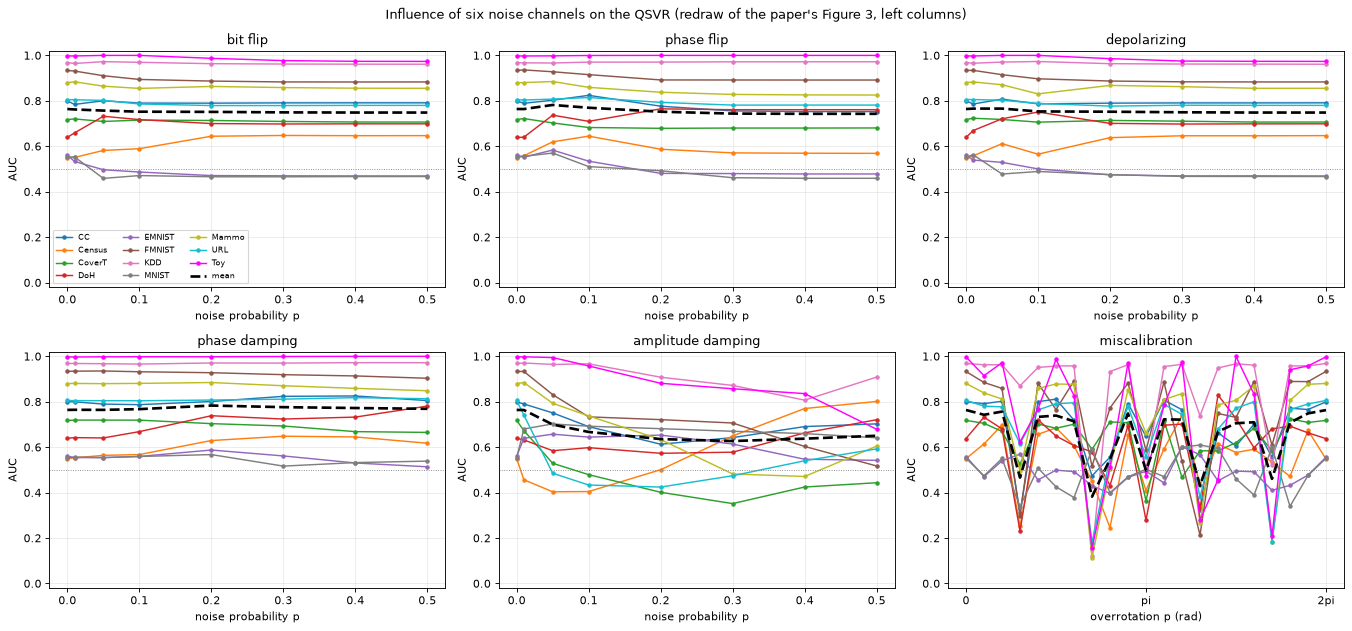

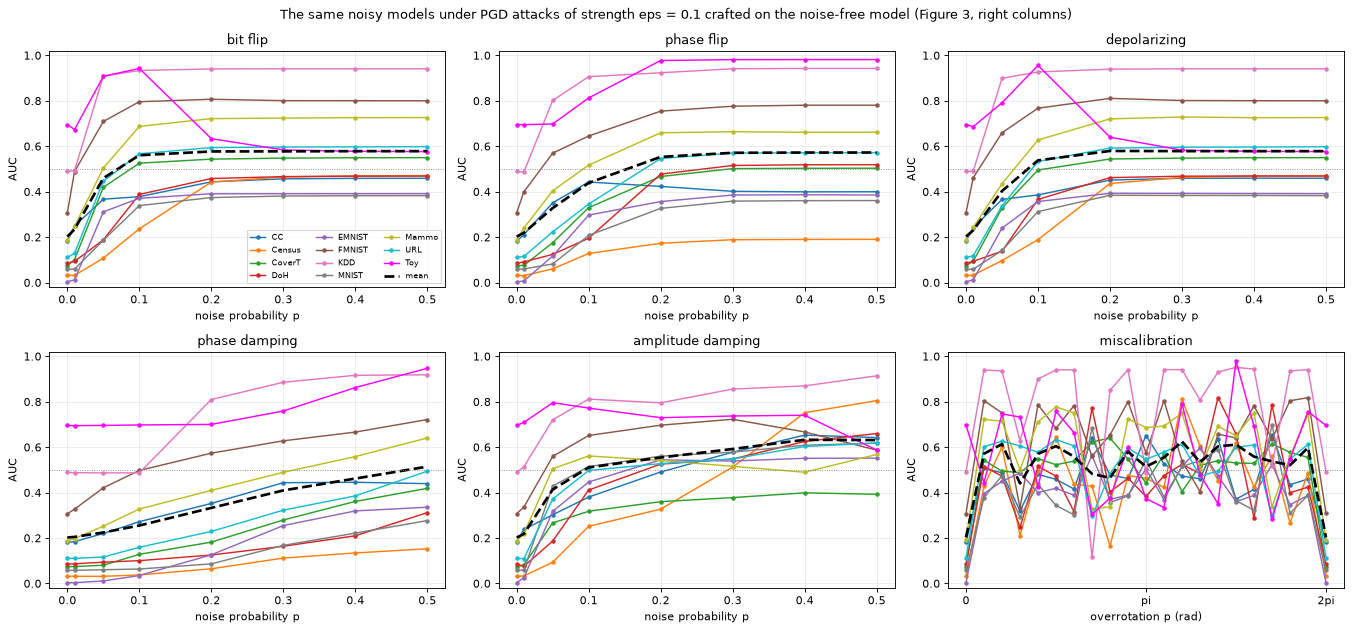

In [18]:
ALL_NOISE = ["bit_flip", "phase_flip", "depolarizing", "phase_damping", "amplitude_damping", "miscalibration"]
def figure3(col, title):
    fig, axes = plt.subplots(2, 3, figsize=(17, 8)); axes = axes.ravel()
    base = NOISE_MEAN[NOISE_MEAN["noise"] == "none"].set_index("dataset")[col]
    for ax, kind in zip(axes, ALL_NOISE):
        sub = NOISE_MEAN[NOISE_MEAN["noise"] == kind]
        for name in DATASETS:
            s = sub[sub["dataset"] == name].sort_values("p")
            xs = np.r_[0.0, s["p"].to_numpy()] if kind != "miscalibration" else s["p"].to_numpy()
            ys = np.r_[base[name], s[col].to_numpy()] if kind != "miscalibration" else s[col].to_numpy()
            ax.plot(xs, ys, marker="o", ms=3, lw=1.3, label=name, color=DS_COLORS[name])
        mean = sub.groupby("p")[col].mean()
        mx = np.r_[0.0, mean.index.to_numpy()] if kind != "miscalibration" else mean.index.to_numpy()
        my = np.r_[base.mean(), mean.to_numpy()] if kind != "miscalibration" else mean.to_numpy()
        ax.plot(mx, my, "k--", lw=2.4, label="mean")
        ax.axhline(0.5, color="grey", lw=0.8, ls=":")
        ax.set_title(kind.replace("_", " ")); ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel("overrotation p (rad)" if kind == "miscalibration" else "noise probability p"); ax.set_ylabel("AUC")
        if kind == "miscalibration":
            ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", "pi", "2pi"])
    axes[0].legend(ncol=3, fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

figure3("AUC_clean", "Influence of six noise channels on the QSVR (redraw of the paper's Figure 3, left columns)")
figure3("AUC_adv", f"The same noisy models under PGD attacks of strength eps = {EPS_NOISY} crafted on the noise-free model (Figure 3, right columns)")


In [19]:
# Paper Table 3: adversarial test kernel of DoH under miscalibration noise, a "good" setting (p = 2.9) and a "bad" one (p = 1.7), eps = 0.1.
d = get_prep("DoH", 0); y = d["y_test"]; Zadv = adv_set("DoH", 0, EPS_NOISY); rows = []
for p in [2.9, 1.7]:
    noise = ("miscalibration", p)
    s_tr = states(d["Z_train"], noise); model = QSVR().fit(kernel_from_states(s_tr, s_tr), d["Z_train"])
    Ka = test_kernel(s_tr, Zadv, noise)
    for c in (0, 1):
        v = Ka[y == c].ravel()                                   # all kernel entries (test row x training row) of class c
        rows.append(dict(p=p, AUC_adv=auc(y, model.score(Ka, Zadv)), **{"class": c}, mean_kernel=f"{v.mean():.3e} +- {v.std():.3e}"))
T3 = pd.DataFrame(rows); display(T3)
print("Paper Table 3:  p = 2.9: AUC 0.98, class 0 1.743e-01, class 1 1.734e-01;   p = 1.7: AUC 0.00, class 0 1.800e-05, class 1 1.796e-05")


,p,AUC_adv,class,mean_kernel
0,2.9,0.6332,0,9.079e-03 +- 4.173e-03
1,2.9,0.6332,1,1.094e-02 +- 3.399e-03
2,1.7,0.2064,0,1.413e-02 +- 1.131e-02
3,1.7,0.2064,1,8.542e-03 +- 5.963e-03


Paper Table 3:  p = 2.9: AUC 0.98, class 0 1.743e-01, class 1 1.734e-01;   p = 1.7: AUC 0.00, class 0 1.800e-05, class 1 1.796e-05


## 9. Adversarial training (Tables 4 and 5)

The attacker perturbs the 100 normal training rows (strength `EPS_TRAIN`), the QSVR is retrained on the perturbed set, and the retrained model is attacked again (adaptive white box, $\epsilon=0.1$). Table 4 compares clean and attacked AUC with and without retraining; Table 5 reports, at the 95th-percentile alarm threshold of the validation normals, the share of attacked normal rows that raise no alarm and the share of attacked anomalies that do.

In [20]:
def alarm_ratios(model, Kval, Zval, s_adv, y):
    """Table 5: share of attacked normal samples that stay below the alarm threshold (tn / (tn + fp)) and share of attacked anomalies above it (tp / (tp + fn))."""
    thr = np.quantile(model.score(Kval, Zval), THRESH_Q)
    return float((s_adv[y == 0] <= thr).mean()), float((s_adv[y == 1] > thr).mean())

def adversarial_training_study(name, draw, eps=EPS_TRAIN):
    d = get_prep(name, draw); Ztr, Zva, Zte, y = d["Z_train"], d["Z_val"], d["Z_test"], d["y_test"]
    m0 = clean_model(name, draw); M0 = attack_parts(m0, Ztr)
    Zadv_te0 = adv_set(name, draw, eps)                                              # attack on the model without retraining
    # adversarial training set: PGD (eps) against the original model, normal training rows pushed to a HIGH reconstruction error
    Ztr_adv = pgd(Ztr, np.zeros(len(Ztr), dtype=int), M0, eps)
    res = {}
    for variant, targets in [("target = attacked input", Ztr_adv), ("target = clean input", Ztr)]:
        m1 = QSVR().fit(q_kernel(Ztr_adv, Ztr_adv), targets)
        M1 = attack_parts(m1, Ztr_adv)
        Zadv_te1 = pgd(Zte, y, M1, eps)                                              # adaptive white-box attack on the RETRAINED model
        res[variant] = dict(
            test_auc=auc(y, m1.score(q_kernel(Zte, Ztr_adv), Zte)), adv_auc=auc(y, score_noiseless(Zadv_te1, M1)),
            ratios=alarm_ratios(m1, q_kernel(Zva, Ztr_adv), Zva, score_noiseless(Zadv_te1, M1), y))
    base = dict(test_auc=auc(y, m0.score(q_kernel(Zte, Ztr), Zte)), adv_auc=auc(y, score_noiseless(Zadv_te0, M0)),
                ratios=alarm_ratios(m0, q_kernel(Zva, Ztr), Zva, score_noiseless(Zadv_te0, M0), y))
    return base, res

t0 = time.time(); rows5 = []
for name in DATASETS:
    for draw in range(N_SEEDS):
        base, res = adversarial_training_study(name, draw)
        r = res["target = attacked input"]; r2 = res["target = clean input"]
        rows5.append(dict(dataset=name, draw=draw,
                          test_with=r["test_auc"], test_without=base["test_auc"], adv_with=r["adv_auc"], adv_without=base["adv_auc"],
                          norm_with=r["ratios"][0], anom_with=r["ratios"][1], norm_without=base["ratios"][0], anom_without=base["ratios"][1],
                          test_with_cleantarget=r2["test_auc"], adv_with_cleantarget=r2["adv_auc"]))
ADVTRAIN = pd.DataFrame(rows5)
T4 = ADVTRAIN.groupby("dataset")[["test_with", "test_without", "adv_with", "adv_without"]].mean().loc[DATASETS]
T4.loc["Mean"] = T4.mean()
T4.columns = ["Test AUC w/ retraining", "Test AUC w/o retraining", "Adv AUC w/ retraining", "Adv AUC w/o retraining"]
print(f"Table 4 (this notebook): adversarial training with eps = {EPS_TRAIN}, attack strength on the test set eps = {EPS_TRAIN}   ({time.time()-t0:.0f} s)")
display(T4.round(2))
T5 = ADVTRAIN.groupby("dataset")[["norm_with", "anom_with", "norm_without", "anom_without"]].mean().loc[DATASETS]
T5.loc["Mean"] = T5.mean(); T5.columns = ["normal, retraining", "anomalous, retraining", "normal, no retraining", "anomalous, no retraining"]
print("Table 5 (this notebook): share of attacked samples classified correctly at the 95th-percentile alarm threshold")
display(T5.round(2))
alt = ADVTRAIN.groupby("dataset")[["test_with_cleantarget", "adv_with_cleantarget"]].mean().loc[DATASETS].mean()
print("Variant with CLEAN reconstruction targets (denoising-style retraining): mean test AUC %.3f, mean adversarial AUC %.3f" % (alt.iloc[0], alt.iloc[1]))


Table 4 (this notebook): adversarial training with eps = 0.1, attack strength on the test set eps = 0.1   (282 s)


,Test AUC w/ retraining,Test AUC w/o retraining,Adv AUC w/ retraining,Adv AUC w/o retraining
dataset,,,,
CC,0.74,0.84,0.14,0.16
Census,0.59,0.57,0.02,0.02
CoverT,0.63,0.72,0.07,0.06
DoH,0.63,0.65,0.11,0.09
EMNIST,0.49,0.56,0.01,0.00
FMNIST,0.88,0.91,0.60,0.42
KDD,0.92,0.97,0.69,0.55
MNIST,0.52,0.56,0.05,0.04
Mammo,0.75,0.87,0.35,0.20


Table 5 (this notebook): share of attacked samples classified correctly at the 95th-percentile alarm threshold


,"normal, retraining","anomalous, retraining","normal, no retraining","anomalous, no retraining"
dataset,,,,
CC,0.90,0.12,0.81,0.08
Census,0.41,0.02,0.44,0.03
CoverT,0.54,0.05,0.62,0.03
DoH,0.68,0.05,0.55,0.09
EMNIST,0.70,0.00,0.63,0.00
FMNIST,0.63,0.51,0.53,0.39
KDD,0.87,0.54,0.56,0.69
MNIST,0.87,0.02,0.85,0.02
Mammo,0.92,0.11,0.88,0.05


Variant with CLEAN reconstruction targets (denoising-style retraining): mean test AUC 0.740, mean adversarial AUC 0.253


## 10. Sensitivity to the three open numbers

The paper does not give the SVR's `C` and `epsilon` or the angle scale. The values in the configuration cell were fixed before any test AUC was computed. The table shows the noise-free mean AUC for a small grid around them, so you can see how much of the headline number depends on these choices. It is *not* used to select the values (that would be test-set tuning).

In [21]:
# Sensitivity of the noise-free AUC to the three numbers the paper does not give. This table is NOT used to pick the values (they were fixed
# in the configuration cell before any test AUC was computed); it shows how much the headline mean depends on them.
rows = []
for sc in [0.5, 1.0, np.pi]:
    for eps in [0.001, 0.01, 0.1]:
        a = []
        for name in DATASETS:
            d = get_prep(name, 0); Ztr, Zte, y = d["Z_train"], d["Z_test"], d["y_test"]
            m = QSVR(eps=eps).fit(q_kernel(Ztr, Ztr, scale=sc), Ztr)
            a.append(auc(y, m.score(q_kernel(Zte, Ztr, scale=sc), Zte)))
        rows.append(dict(angle_scale=round(sc, 3), svr_epsilon=eps, mean_AUC=np.mean(a), min_AUC=np.min(a), max_AUC=np.max(a)))
display(pd.DataFrame(rows).round(3))


,angle_scale,svr_epsilon,mean_AUC,min_AUC,max_AUC
0,0.500,0.001,0.736,0.476,1.000
1,0.500,0.010,0.746,0.460,1.000
2,0.500,0.100,0.736,0.422,1.000
3,1.000,0.001,0.767,0.477,0.999
4,1.000,0.010,0.768,0.546,0.997
5,1.000,0.100,0.713,0.414,1.000
6,3.142,0.001,0.799,0.594,1.000
7,3.142,0.010,0.800,0.584,1.000
8,3.142,0.100,0.768,0.478,1.000


## 11. Paper versus this notebook, claim by claim

Verdicts: **reproduced** when the number is within the stated tolerance (a 100-sample test set gives an AUC standard error of about 0.05, so per-dataset tolerances are 0.05 AUC and tolerances on means over eleven datasets are 0.03-0.05), **not reached** / **exceeded** with the gap otherwise, and **cannot be checked** when the claim needs hardware or a number the paper does not report. Qualitative claims are turned into a numerical rule that is written next to them.

In [22]:
PAPER_T4 = pd.DataFrame({  # Table 4 of the paper: test AUC and adversarial AUC (eps = 0.1 as in Figure 3), with and without adversarial training
    "test_with": [0.85, 0.62, 0.68, 0.63, 0.91, 0.44, 0.71, 0.74, 0.62, 0.59, 1.00],
    "test_without": [0.90, 0.53, 0.68, 0.62, 0.88, 0.56, 0.90, 0.95, 0.67, 0.60, 1.00],
    "adv_with": [0.37, 0.05, 0.00, 0.17, 0.73, 0.18, 0.46, 0.22, 0.11, 0.08, 1.00],
    "adv_without": [0.31, 0.12, 0.00, 0.14, 0.74, 0.08, 0.43, 0.19, 0.07, 0.08, 0.95]},
    index=["CC", "Census", "DoH", "EMNIST", "FMNIST", "CoverT", "KDD", "Mammo", "MNIST", "URL", "Toy"]).loc[DATASETS]
PAPER_T5_MEAN = dict(norm_with=0.97, anom_with=0.23, norm_without=0.96, anom_without=0.22)
verdicts = []
def add(claim, paper, ours, ok, kind="within tolerance", note=""):
    verdicts.append(dict(claim=claim, paper=paper, notebook=ours, verdict=ok, note=note))
def judge(ours, paper, tol, higher_is_exceed=True):
    if abs(ours - paper) <= tol: return "reproduced"
    return ("exceeded" if ours > paper else "not reached") + f" ({ours - paper:+.2f})"

T4n = ADVTRAIN.groupby("dataset")[["test_with", "test_without", "adv_with", "adv_without"]].mean().loc[DATASETS]
m_clean = float(QSVR_AUC.mean())
# 1-2. noise-free test AUC (Table 4 'Test AUC w/o retraining'; conclusions: 0.76)
add("Noise-free mean test AUC over 11 datasets", "0.75 (Table 4) / 0.76 (Sec. 5)", f"{m_clean:.2f}", judge(m_clean, 0.755, 0.03), note="tolerance 0.03 on a mean of 11")
diff = (QSVR_AUC - PAPER_T4["test_without"]).abs(); k_ok = int((diff <= 0.05).sum())
add("Per-dataset noise-free test AUC (Table 4)", "11 values", f"{k_ok}/11 within 0.05", "reproduced" if k_ok >= 9 else f"not reached ({k_ok}/11 within 0.05)",
    note="largest gaps: " + ", ".join(f"{n} {QSVR_AUC[n]:.2f} vs {PAPER_T4['test_without'][n]:.2f}" for n in diff.sort_values(ascending=False).index[:3]))
# 2b. classical competitors (predecessor paper, quoted in the introduction: "comparable to a classical SVR, marginal superiority over the other models")
cs, cae, oc, iso = (float(BASE_MEAN[c].mean()) for c in ["CSVR (RBF kernel)", "CAE (5-3-5 MLP)", "One-class SVM (RBF)", "Isolation Forest"])
add("QSVR is comparable to a classical SVR and marginally ahead of the other (autoencoder-type) competitors", "comparable to CSVR, marginally ahead of the rest",
    f"QSVR {m_clean:.2f}, CSVR {cs:.2f}, CAE {cae:.2f}, OC-SVM {oc:.2f}, IsoForest {iso:.2f}", "reproduced" if abs(m_clean - cs) <= 0.03 and m_clean >= max(cae, oc, iso) - 0.01 else "not reached",
    note="rule: |QSVR - CSVR| <= 0.03 and QSVR >= best of CAE / OC-SVM / IsoForest - 0.01 (mean AUC over datasets); the paper only quotes this claim from its predecessor")
# 3. attack curve
cv = ADV_CURVE.groupby(["dataset", "eps"])["AUC"].mean().unstack("eps")
e0, e1, e3 = 0.0, 0.01, 0.3
d_doh0, d_doh1 = cv.loc["DoH", e0], cv.loc["DoH", e1]
add("DoH AUC at eps = 0 -> 0.01 (order-of-magnitude drop)", "0.67 -> 0.06", f"{d_doh0:.2f} -> {d_doh1:.2f}",
    "reproduced" if abs(d_doh0 - 0.67) <= 0.10 and abs(d_doh1 - 0.06) <= 0.10 else f"not reached (clean gap {d_doh0-0.67:+.2f}, attacked gap {d_doh1-0.06:+.2f})")
drops = {n: cv.loc[n, e0] - cv.loc[n, e1] for n in DATASETS}
non_toy = [n for n in DATASETS if n != "Toy"]; n_drop = sum(drops[n] > 0.02 for n in non_toy)
add("AUC falls at eps = 0.01 for every dataset except Toy", "10 of 10 fall, Toy unchanged", f"{n_drop}/10 fall by > 0.02; Toy change {drops['Toy']:+.3f}",
    "reproduced" if n_drop == 10 and abs(drops["Toy"]) <= 0.02 else "not reached", note="weak: " + ", ".join(f"{n} {drops[n]:+.2f}" for n in non_toy if drops[n] <= 0.02) if n_drop < 10 else "")
mean3 = float(cv[e3].mean())
add("AUC approaches 0 at eps = 0.3", "close to 0.0 for all datasets", f"mean AUC {mean3:.3f}, max {cv[e3].max():.3f}", "reproduced" if mean3 <= 0.10 else f"not reached (mean {mean3:.2f})")
# 4. adversarial AUC and training (Table 4)
a_wo, a_w = float(T4n["adv_without"].mean()), float(T4n["adv_with"].mean())
add("Mean adversarial AUC without retraining (eps = 0.1)", "0.28", f"{a_wo:.2f}", judge(a_wo, 0.28, 0.05))
add("Mean adversarial AUC with adversarial training", "0.31", f"{a_w:.2f}", judge(a_w, 0.31, 0.05))
n_up = int((T4n["adv_with"] > T4n["adv_without"]).sum())
add("Adversarial training does not reliably harden the QSVR", "AUC gain +0.03 (7/11 datasets improve), AUC stays < 0.5 except FMNIST and Toy",
    f"gain {a_w - a_wo:+.2f} ({n_up}/11 improve), mean adversarial AUC {a_w:.2f}", "reproduced" if (a_w - a_wo) < 0.10 and a_w < 0.5 else "not reached",
    note="rule: mean gain < 0.10 and mean adversarial AUC < 0.5")
t_wo, t_w = float(T4n["test_without"].mean()), float(T4n["test_with"].mean())
add("Adversarial training slightly lowers the clean test AUC", "0.75 -> 0.71 (-0.04)", f"{t_wo:.2f} -> {t_w:.2f} ({t_w - t_wo:+.2f})",
    "reproduced" if abs((t_w - t_wo) - (-0.04)) <= 0.05 else judge(t_w - t_wo, -0.04, 0.05))
r5 = ADVTRAIN[["norm_with", "anom_with", "norm_without", "anom_without"]].mean()
add("Table 5: mean share of attacked samples classified correctly (normal / anomalous)", "0.97 / 0.23 (retraining), 0.96 / 0.22 (none)",
    f"{r5['norm_with']:.2f} / {r5['anom_with']:.2f} (retraining), {r5['norm_without']:.2f} / {r5['anom_without']:.2f} (none)",
    "reproduced" if abs(r5["norm_without"] - 0.96) <= 0.05 and abs(r5["anom_without"] - 0.22) <= 0.10 else "not reached", note="threshold choice (95th percentile of validation normals) is ours")
# 5. noise study
N = NOISE_MEAN.copy(); base = N[N["noise"] == "none"].set_index("dataset")["AUC_clean"]; base_adv = N[N["noise"] == "none"].set_index("dataset")["AUC_adv"]
def mean_abs_shift(kind):
    s = N[N["noise"] == kind]; return float((s["AUC_clean"] - s["dataset"].map(base)).abs().mean())
shifts = {k: mean_abs_shift(k) for k in NOISE_TYPES + ["miscalibration"]}
robust = ["bit_flip", "phase_flip", "depolarizing", "phase_damping"]
add("Robust to bit flip, phase flip, depolarizing and phase damping (AUC stays rather stable)", "qualitative",
    ", ".join(f"{k} {shifts[k]:.2f}" for k in robust) + "  (mean |AUC shift|)", "reproduced" if all(shifts[k] <= 0.10 for k in robust) else "not reached",
    note="rule: mean |AUC - AUC(p=0)| over datasets and probabilities <= 0.10")
add("Amplitude damping is the most damaging incoherent channel", "qualitative", f"amplitude damping {shifts['amplitude_damping']:.2f} vs max of the other four {max(shifts[k] for k in robust):.2f}",
    "reproduced" if shifts["amplitude_damping"] > max(shifts[k] for k in robust) else "not reached")
ad = N[N["noise"] == "amplitude_damping"]; low_ps = [p for p in NOISE_PROBS if p in (0.1, 0.2)]
decr = {n: float(np.mean([base[n] - ad[(ad.dataset == n) & np.isclose(ad.p, p)]["AUC_clean"].iloc[0] for p in low_ps])) for n in DATASETS}
n_dec = sum(decr[n] > 0.02 for n in DATASETS)
add("Amplitude damping lowers the AUC at p = 0.1-0.2 on all datasets except CoverT and URL", "9 of 11 fall, CoverT and URL do not", f"{n_dec}/11 fall by > 0.02 (CoverT {decr['CoverT']:+.2f}, URL {decr['URL']:+.2f})",
    "reproduced" if n_dec >= 8 and decr["CoverT"] <= 0.02 and decr["URL"] <= 0.02 else "not reached", note="p values used: " + str(low_ps))
hi = ad[np.isclose(ad.p, 0.5)]["AUC_clean"].mean()
add("At high amplitude damping the AUC approaches a random classifier", "about 0.5", f"mean AUC at p = 0.5: {hi:.2f}", "reproduced" if abs(hi - 0.5) <= 0.10 else judge(hi, 0.5, 0.10))
mc = N[N["noise"] == "miscalibration"].sort_values("p"); K = len(MISCAL_GRID) - 1
corrs = []
for n in DATASETS:
    a = mc[mc.dataset == n]["AUC_clean"].to_numpy()
    x, y2 = a[: K // 2 + 1], a[K // 2:]
    if np.std(x) > 1e-9 and np.std(y2) > 1e-9: corrs.append(np.corrcoef(x, y2)[0, 1])
cmean = float(np.mean(corrs)) if corrs else float("nan")
add("Miscalibration curves are roughly periodic with period pi", "periodicity of about pi", f"mean correlation of AUC(p) and AUC(p+pi): {cmean:.2f} ({len(corrs)} datasets)", "reproduced" if cmean >= 0.5 else "not reached",
    note="rule: correlation >= 0.5")
plateau = mc[(mc.p > 0.25 * np.pi) & (mc.p < 0.75 * np.pi)].groupby("dataset")["AUC_clean"].mean()
add("Miscalibration above ~0.25 pi returns to a plateau near the zero-noise AUC", "plateau similar to zero noise", f"mean plateau {plateau.mean():.2f} vs zero-noise {base.mean():.2f}",
    "reproduced" if abs(plateau.mean() - base.mean()) <= 0.10 else judge(plateau.mean(), base.mean(), 0.10))
# 6. noise under attack
adv_inc = N[N["noise"].isin(NOISE_TYPES)].groupby(["noise", "p"])["AUC_adv"].mean()
best_adv = float(adv_inc.max()); plateau_adv = float(N[N["noise"].isin(NOISE_TYPES) & np.isclose(N["p"], max(NOISE_PROBS))]["AUC_adv"].mean())
add("Under attack, incoherent noise never lifts the AUC clearly above a random classifier", "attacked AUC plateaus at about 0.5", f"best mean attacked AUC over all settings {best_adv:.2f}; at p = {max(NOISE_PROBS)} {plateau_adv:.2f}",
    "reproduced" if best_adv <= 0.60 else f"not reached (best {best_adv:.2f})", note="rule: best mean attacked AUC <= 0.60")
mad = N[N["noise"] == "miscalibration"]; ds_up = [n for n in DATASETS if mad[mad.dataset == n]["AUC_adv"].max() > max(0.5, base_adv[n])]
add("Miscalibration spikes lift the attacked AUC above both zero noise and 0.5 only on some datasets", "DoH, FMNIST, KDD, Toy, Census, Mammo", ", ".join(ds_up) if ds_up else "none",
    "cannot be checked (qualitative)", note="paper's list for comparison; depends on the exact miscalibration model")
# 7. Table 3
v1 = T3.set_index(["p", "class"])["mean_kernel"]; g = lambda s: float(s.split(" +- ")[0])
ratio = g(v1[(2.9, 0)]) / max(g(v1[(1.7, 0)]), 1e-300)
add("DoH under miscalibration: kernel values at p = 2.9 vs p = 1.7 differ by about four orders of magnitude (Table 3)", "ratio about 1e4 (0.174 vs 1.8e-5)", f"ratio {ratio:.1e} ({g(v1[(2.9,0)]):.2e} vs {g(v1[(1.7,0)]):.2e})",
    "reproduced" if 1e3 <= ratio <= 1e5 else f"not reached (ratio {ratio:.1e})")
# 8. hardware
hw_sim = float(HW.loc["MEAN", "AUC_simulated_30_50"])
add("Noise-free simulation on the hardware split (30 train / 50 test): mean AUC", "0.76", f"{hw_sim:.2f}", judge(hw_sim, 0.76, 0.05))
add("Hardware qc-QSVR mean AUC and its 0.04 drop against simulation", "0.72 (-0.04), better than simulation on 2 of 11 datasets", f"depolarizing stand-in drop {float(HW.loc['MEAN','AUC_simulated_30_50']-HW.loc['MEAN','AUC_hardware_like_noise']):+.3f}", "cannot be checked", note="needs the IBM Ehningen device")
nm = (len(NOISE_LIST) - 1) * len(DATASETS)
add("Number of noisy models simulated per data draw", "over 500", f"{nm} per draw ({nm * N_SEEDS_NOISE} in total)", "reproduced" if nm > 500 else "not reached (FAST grid)")
VERDICTS = pd.DataFrame(verdicts)
pd.set_option("display.max_colwidth", 90)
display(VERDICTS[["claim", "paper", "notebook", "verdict"]])
print("\nNotes on the rules behind the verdicts:")
for r in verdicts:
    if r["note"]: print(" -", r["claim"][:70], "::", r["note"])
print("\nTally:", VERDICTS["verdict"].str.split(" ").str[0].value_counts().to_dict())


,claim,paper,notebook,verdict
0,Noise-free mean test AUC over 11 datasets,0.75 (Table 4) / 0.76 (Sec. 5),0.77,reproduced
1,Per-dataset noise-free test AUC (Table 4),11 values,4/11 within 0.05,not reached (4/11 within 0.05)
2,QSVR is comparable to a classical SVR and marginally ahead of the other (autoencoder-t...,"comparable to CSVR, marginally ahead of the rest","QSVR 0.77, CSVR 0.79, CAE 0.73, OC-SVM 0.71, IsoForest 0.75",reproduced
3,DoH AUC at eps = 0 -> 0.01 (order-of-magnitude drop),0.67 -> 0.06,0.65 -> 0.47,"not reached (clean gap -0.02, attacked gap +0.41)"
4,AUC falls at eps = 0.01 for every dataset except Toy,"10 of 10 fall, Toy unchanged",10/10 fall by > 0.02; Toy change +0.004,reproduced
5,AUC approaches 0 at eps = 0.3,close to 0.0 for all datasets,"mean AUC 0.012, max 0.108",reproduced
6,Mean adversarial AUC without retraining (eps = 0.1),0.28,0.22,not reached (-0.06)
7,Mean adversarial AUC with adversarial training,0.31,0.28,reproduced
8,Adversarial training does not reliably harden the QSVR,"AUC gain +0.03 (7/11 datasets improve), AUC stays < 0.5 except FMNIST and Toy","gain +0.05 (9/11 improve), mean adversarial AUC 0.28",reproduced
9,Adversarial training slightly lowers the clean test AUC,0.75 -> 0.71 (-0.04),0.77 -> 0.72 (-0.05),reproduced



Notes on the rules behind the verdicts:
 - Noise-free mean test AUC over 11 datasets :: tolerance 0.03 on a mean of 11
 - Per-dataset noise-free test AUC (Table 4) :: largest gaps: URL 0.82 vs 0.60, CoverT 0.72 vs 0.56, MNIST 0.56 vs 0.67
 - QSVR is comparable to a classical SVR and marginally ahead of the othe :: rule: |QSVR - CSVR| <= 0.03 and QSVR >= best of CAE / OC-SVM / IsoForest - 0.01 (mean AUC over datasets); the paper only quotes this claim from its predecessor
 - Adversarial training does not reliably harden the QSVR :: rule: mean gain < 0.10 and mean adversarial AUC < 0.5
 - Table 5: mean share of attacked samples classified correctly (normal / :: threshold choice (95th percentile of validation normals) is ours
 - Robust to bit flip, phase flip, depolarizing and phase damping (AUC st :: rule: mean |AUC - AUC(p=0)| over datasets and probabilities <= 0.10
 - Amplitude damping lowers the AUC at p = 0.1-0.2 on all datasets except :: p values used: [0.1, 0.2]
 - Miscalibration 

## Reading the paper critically

The numbers below are from the full run (`FAST_MODE = False`: three data draws, the paper's noise grids, 50 PGD iterations, 616 noisy models per data draw). The FAST demo gives the same qualitative picture with larger scatter.

**What reproduces.** The noise-free mean AUC over the eleven datasets is 0.77 (paper 0.75 / 0.76). The QSVR is comparable to a classical RBF-kernel SVR on the same five features (0.77 vs 0.79) and a little ahead of the autoencoder, one-class SVM and isolation forest. The attack results are strong and match the paper in shape: AUC falls for ten of eleven datasets already at $\epsilon = 0.01$ while Toy is unchanged, and it is essentially zero at $\epsilon = 0.3$ (mean 0.01); the mean attacked AUC at $\epsilon = 0.1$ is 0.22 without and 0.28 with adversarial training (paper 0.28 and 0.31), so adversarial training helps a little but never makes the model robust. Bit flip, phase flip, depolarizing and phase damping change the AUC by only 0.02-0.03 on average, amplitude damping is clearly the worst incoherent channel (0.15), and the miscalibration curves are correlated with their own copy shifted by $\pi$ (0.53).

**What does not reproduce, and why that matters.**
- *Per dataset, only 4 of 11 noise-free AUCs lie within 0.05 of Table 4* (largest gaps: URL 0.82 vs 0.60, CoverT 0.72 vs 0.56, MNIST 0.56 vs 0.67). The agreement of the mean is therefore partly cancellation. Preprocessing details the paper defers to its predecessor (how PCA and scaling were fitted, which rows were drawn) plausibly decide these gaps. Across our three independent data draws the per-dataset AUC has a standard deviation of 0.03 on average and the sensitivity table shows that the three open numbers (angle scale, `C`, `epsilon`) alone move the mean between 0.71 and 0.80.
- *DoH is less fragile here.* The paper reports 0.67 -> 0.06 at $\epsilon = 0.01$ and explains it by the dataset's tiny feature variance. We get 0.65 -> 0.47. Whether a perturbation of 0.01 is large depends entirely on how features are normalised; the paper does not give that scaling, so DoH's outlier status cannot be confirmed or refuted.
- *Table 3 (kernel values of 0.17 vs 1.8e-5 under miscalibration) is not reproduced*: our attacked kernel entries are around 1e-2 for both settings. The coherent-noise model (axis, position of the over-rotation) is under-specified, and this is the one claim that depends on it quantitatively.
- *Weaker plateaus.* The paper reports high amplitude damping and attacked noisy models settling at about 0.5. We see 0.65 for amplitude damping at $p = 0.5$ and a best mean attacked AUC of 0.63 for incoherent noise, i.e. noise partly *restores* the ranking after a transferred attack, and CoverT and URL do fall at $p = 0.1$-0.2 (the paper says they do not).
- *Table 5* depends on an alarm threshold the paper does not state; our 95th-percentile rule gives 0.71 / 0.21 against the paper's 0.97 / 0.23 for the retrained model, which says more about the threshold than about the model.

**Points about the paper's conclusions.**
1. *"Highly vulnerable" is not a quantum-versus-classical statement.* The paper never attacks a classical SVR with the same protocol. With five features scaled to [0, 1], $\epsilon = 0.1$ is a tenth of the whole range and the attacker knows the label; an RBF-SVR on the same features is very likely just as fragile (Exercise 5). The result shows that semi-supervised reconstruction scores on low-dimensional data are easy to move, not that the quantum kernel is the culprit.
2. *AUC robustness is not kernel robustness.* Under bit flip with $p = 0.1$ a kernel entry that is 0.97 noise-free drops to about 0.09 (see the equivalence table), yet the AUC barely moves. The SVR re-scales its dual coefficients, so the ranking of reconstruction errors survives while the kernel itself collapses. "Robust to noise" is a statement about a ranking metric on 100 test samples.
3. *The hardware gap is within sampling noise.* A 0.04 AUC difference on 50 test rows is smaller than the standard error of a single AUC (about 0.05), and the explanation that hardware noise acts like a denoising autoencoder is offered without a test. Our depolarizing stand-in changes the mean AUC by -0.004, so noise at the calibration level of Table 1 is not what separates simulation and hardware; readout error, shot noise and mitigation, which the stand-in omits, are the untested candidates.
4. *Several "near chance" datasets are a representation bottleneck.* After PCA to five components, EMNIST, MNIST and Census keep only 27-36 % of the variance, and every competitor, classical ones included, is near chance on them (the supervised random forest on the same five features reaches 0.66-0.84, so the information is partly there). Differences between the quantum and classical *models* on such datasets say little about the models.
5. *Adversarial training on normals only cannot teach the model what an evasive anomaly looks like*, which is the paper's own explanation and fits our numbers (gain +0.05, no dataset reaches 0.9). A defence would need to use the anomaly side or a different score.
6. *Single draw, no error bars.* The paper argues the SVR is deterministic, but the 100-row test set and the 100 training rows are random draws. Per-dataset AUCs and especially statements about individual datasets (DoH, CoverT, URL) carry an uncertainty of about 0.05 and should not be over-read.

**What this notebook did not do.** No real hardware, no quantum autoencoder baseline, no trainable kernel (the paper's own recommendation), and one fixed entanglement pattern. Verdicts on qualitative claims use the numerical rules printed under the table, which are our reading, not the paper's definitions."""

## Exercises

1. **Open numbers.** Change `ANGLE_SCALE` to `np.pi` and `SVR_EPS` to `0.001` in the configuration cell and re-run. Which datasets gain or lose AUC? Compare with the sensitivity table of section 10. Why is it dangerous to pick these numbers by looking at the test AUC of an anomaly detector that never saw an anomaly?
2. **Noise placement.** The notebook inserts the noise channel after *every* gate. Change `circuit_ops` in the simulator so that noise acts only after the `IsingZZ` layer (or only once at the end of $U(x_j)$). How do the amplitude-damping and bit-flip curves of Figure 3 change? Re-run the equivalence check against PennyLane after your change.
3. **Better attack, better defence.** Replace the sign-gradient step by a random start plus a larger number of PGD iterations (`PGD_ITERS = 200`) and by a target-clean-input variant of adversarial training. Does the mean adversarial AUC of section 9 move beyond the paper's 0.31? Which of the two changes matters more?
4. **A different kernel.** Replace the `IsingZZ(x_q x_{q+1})` layer by a ring or a fully connected pattern, or by nothing at all (a product kernel). Which datasets care? Relate the answer to the paper's closing advice to use dataset-specific or trainable kernels.
5. **Why is Toy special?** Toy is linearly separable with a gap of 0.4, yet the attack with $\epsilon=0.3$ drives its AUC to the floor. Using the reconstruction error of the clean and attacked rows, explain what the model is doing; then check what the *classical* RBF-SVR of section 5 gives under the same attack (reuse `pgd` with a model built from its dual coefficients and a numerical gradient).